# 02. Data Analysis & Visualization
Questo notebook è dedicato all'analisi dei dataset contenenti informazioni sul mondo degli anime.
Questo studio mira a comprendere i trend storici, le distribuzioni tra valutazioni, generi e demografiche, e le preferenze degli utenti.

### Indice
- **Data Loading**  
Caricamento dei dataset
- **Evoluzione Temporale dell'Industria**   
Analisi dell’andamento nel tempo della produzione di anime e dei principali indicatori dell’industria.
- **Analisi Correlativa tra Generi e Target Demografici**   
Studio della distribuzione dei generi e delle demografiche di riferimento, con particolare attenzione alle relazioni tra queste categorie.
- **Indagine degli utenti**  
Analisi dei gusti, delle preferenze e delle caratteristiche principali dei fan degli anime divisi per categorie.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import plotly.graph_objects as go
from functions.utils import *

##  Data Loading

In questa sezione vengono caricati i dataset già puliti
e preparati nel notebook precedente. L’obiettivo è rendere i dati
pronti per l’analisi e garantire che i tipi di dato (dtypes) siano
corretti e coerenti.  
Alcune operazioni di conversione dei tipi di dato erano già state effettuate
nel notebook precedente; tuttavia, poiché Pandas non mantiene i tipi al
riaprirsi del file, le conversioni dovranno essere eseguite nuovamente.

In [2]:
characters_df = pd.read_csv("../data/processed/Characters_cleaned.csv")
character_anime_works_df = pd.read_csv("../data/processed/Character_anime_works_cleaned.csv")
character_nicknames_df = pd.read_csv("../data/processed/Character_nicknames_cleaned.csv")
details_df = pd.read_csv("../data/processed/Details_cleaned.csv")
favs_df = pd.read_csv("../data/processed/Favs_cleaned.csv")
person_alternate_names_df = pd.read_csv("../data/processed/Person_alternate_names_cleaned.csv")
person_anime_works_df = pd.read_csv("../data/processed/Person_anime_works_cleaned.csv")
person_voice_works_df = pd.read_csv("../data/processed/Person_voice_works_cleaned.csv")
person_details_df = pd.read_csv("../data/processed/Person_details_cleaned.csv")
profiles_df = pd.read_csv("../data/processed/Profiles_cleaned.csv")
ratings_df = pd.read_csv("../data/processed/Ratings_cleaned.csv")
recommendations_df = pd.read_csv("../data/processed/Recommendations_cleaned.csv")
stats_df = pd.read_csv("../data/processed/Stats_cleaned.csv")

Le colonne contenenti date vengono convertite in
tipo `datetime` per consentire operazioni temporali corrette.

In [29]:
# Trasformazione in datetime delle colonne nei dataset person_details, profiles e details
person_details_df = convert_to_datetime(person_details_df, "birthday")
profiles_df = convert_to_datetime(profiles_df, "joined")
profiles_df = convert_to_datetime(profiles_df, "birthday")
details_df = convert_to_datetime(details_df, "start_date")
details_df = convert_to_datetime(details_df, "end_date")

Le colonne numeriche che contengono solo valori interi ma includono
  valori NaN vengono convertite in `Int64` (tipo intero
  compatibile con NaN), evitando così che siano trattate come float64.

In [4]:
# Dataset Details
details_df["year"] = details_df["year"].astype("Int64")
details_df["scored_by"] = details_df["scored_by"].astype("Int64")
details_df["rank"] = details_df["rank"].astype("Int64")
details_df["episodes"] = details_df["episodes"].astype("Int64")
# Dataset Characters
characters_df["favorites"] = characters_df["favorites"].astype("Int64")
characters_df["character_mal_id"] = characters_df["character_mal_id"].astype(int)
# Dataset Profiles
profiles_df["watching"] = profiles_df["watching"].astype("Int64")
profiles_df["completed"] = profiles_df["completed"].astype("Int64")
profiles_df["on_hold"] = profiles_df["on_hold"].astype("Int64")
profiles_df["dropped"] = profiles_df["dropped"].astype("Int64")
profiles_df["plan_to_watch"] = profiles_df["plan_to_watch"].astype("Int64")

## 1. Evoluzione Temporale dell'Industria

L’animazione giapponese ha conosciuto una crescita significativa nel corso del XX e XXI secolo.    
Per questa analisi sono stati considerati solo gli anime narrativi principali, escludendo titoli di tipo *Music*, *CM* (Commercials) e *PV* (Promotional Videos).  
I dati relativi al 2026 non sono stati presi in considerazione poiché parziali e non significativi.  
Per gli anime privi di anno è stato utilizzato l’anno di `start_date`.  

### Evoluzione della produzione annuale di anime

Gli anime sono diventati un fenomeno globale che appassiona milioni di fan in tutto il mondo.  
Ma come si è evoluta la produzione annuale nel tempo? 

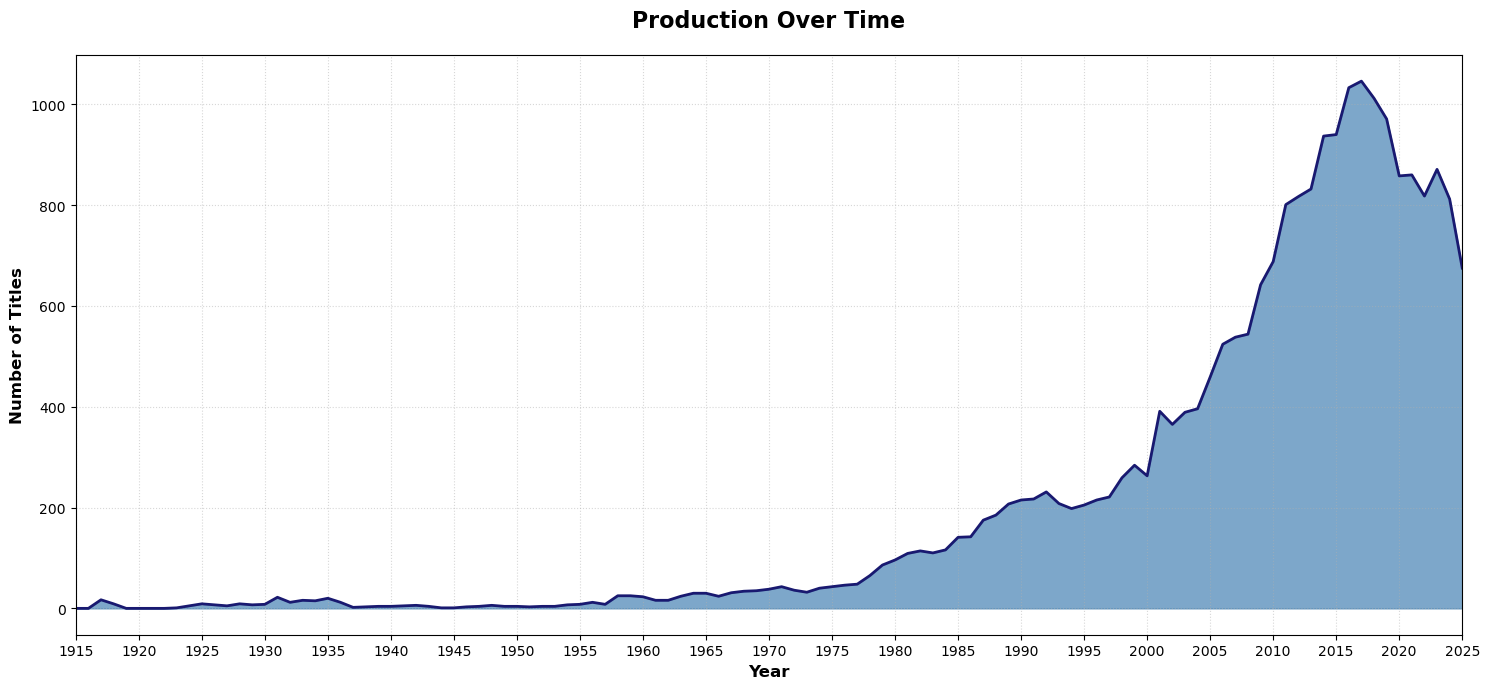

In [5]:
# pulizia di details_df tramite get_cleaned_details: copia dove esclude i tipi non narrativi e prende l'anno da start date in case non ci fosse year
details_copy = get_cleaned_details(details_df)
# raggruppiamo per anno, mettiamo a 0  gli anni senza titoli
title_counts = details_copy.groupby('year_filled')['mal_id'].count().reindex(range(1915, 2026), fill_value=0).reset_index()
title_counts.columns = ['year', 'count']
# creazione grafico (area chart)
plt.figure(figsize=(15, 7))
plt.plot(title_counts['year'], title_counts['count'], color="midnightblue", lw=2) 
plt.fill_between(title_counts['year'], title_counts['count'], color="steelblue", alpha=0.7)
plt.grid(linestyle=':', alpha=0.5)
# personalizzazione assi
plt.title('Production Over Time', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.xlim(1915, 2025)
plt.xticks(ticks=range(1915, 2026, 5))

plt.tight_layout()
plt.show()

All'inizio la produzione di anime era quasi nulla, con 0, massimo 2 titoli all’anno. Gli anime erano per lo più cortometraggi sperimentali destinati principalmente ai cinema. La televisione non era ancora diffusa, quindi non esistevano serie TV come quelle che conosciamo oggi.
 
È solo tra il **1956-1975** che il trend inizia a cambiare. L’avvento della televisione favorisce la nascita dei primi anime televisivi. La produzione annua cresce e nascono opere iconiche come *Lupin III*, *Rocky Joe* e *Heidi* che che contribuiscono ad attirare sempre più l’interesse del pubblico e a stimolare la produzione di anime televisivi.

Con il passare degli anni, **tra il 1976 e il 2000**, l'industria entra in una fase di crescita. Questo periodo vede la nascita di grandi franchise come *Dragon Ball*, *One Piece*, *Neon Genesis Evangelion* e *Cowboy Bebop*. Gli anime diventano un fenomeno globale e la produzione annuale aumenta rapidamente.

Il vero boom avviene **tra il 2001 e il 2017**: Il numero di titoli prodotti ogni anno cresce esponenzialmente, raggiungendo il suo picco massimo nel 2017. Alcuni titoli rappresentativi di questo periodo sono *Attack on Titan*, *One Punch Man* e *My Hero Academia*. La nascita delle piattaforme streaming come Netflix e CrunchyRoll accelerano ulteriormente la produzione e la diffusione degli anime.

Negli **anni più recenti** (dal 2018 a oggi) la produzione segna un calo rispetto agli anni precedenti. Questo riflette un mercato ormai saturo e competitivo, dove gli studios selezionano con un po' più attenzione i progetti per evitare rischi finanziari.

>**Analisi Complessiva**  
L’evoluzione della produzione anime mostra tre fasi principali: una fase iniziale lenta, una crescita rapida e un periodo di moderata discesa recente. La crescita è stata favorita dalla televisione, dall’espansione internazionale e dalle innovazioni tecnologiche nell’animazione digitale. Negli ultimi anni la discesa della produzione indica un mercato competitivo dove gli studios prestano maggiore attenzione alla qualità rispetto alla quantità.


### Distribuzione della produzione annuale per fonte

Non tutti gli anime nascono allo stesso modo: alcuni sono storie completamente nuove (opere originali), mentre altri sono adattamenti di  manga o giochi già famosi. Ma quali sono i più adattati?  
- Il grafico qui sotto mostra quali sono le 5 fonti principali più usate dagli studi di produzione.   
- La categoria `Unknown` è stata esclusa, in quanto non rilevante ai fini dell’analisi.  

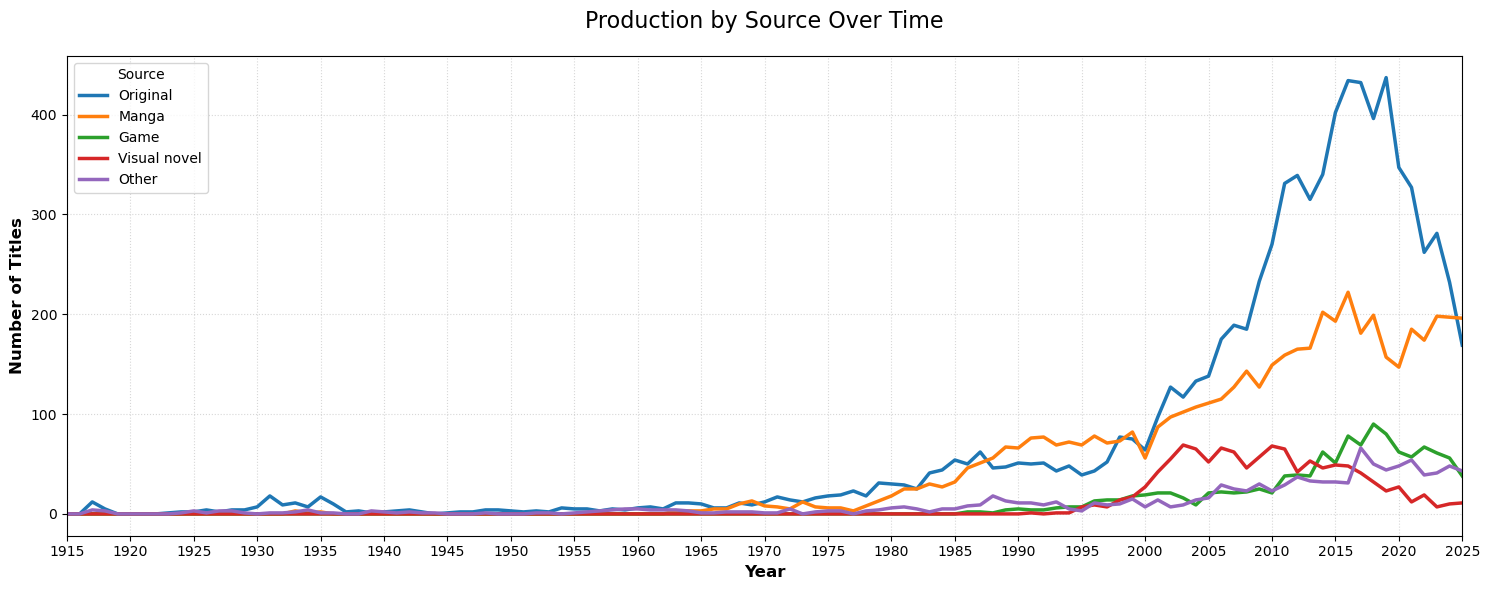

In [6]:
# preparazione dati tramite funzione
details_copy = get_cleaned_details(details_df)
# escludiamo la categoria unknown
source = details_copy[(details_copy['source'].notna()) & (details_copy['source'] != 'Unknown')]
# conteggio: prima troviamo le top 5 e poi contiamo
top_sources = source['source'].value_counts().nlargest(5).index.tolist()
source = source[(source['source'].isin(top_sources))]
source_count = source.groupby(['year_filled', 'source']).size().unstack(fill_value=0).reindex(range(1915, 2026), fill_value=0)
source_count = source_count.reindex(columns=top_sources)
# creazione grafico
plt.figure(figsize=(15,6))
source_count.plot(kind='line', ax=plt.gca(), linewidth=2.5)
plt.grid(linestyle=':', alpha=0.5)
# personalizzazione assi
plt.title('Production by Source Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.xlim(1915, 2025)
plt.xticks(ticks=range(1915, 2026, 5))
plt.legend(title='Source', loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

 
Nei primi lavori di animazione, la maggior parte degli anime erano *original*, mentre gli adattamenti da *manga* erano pochi. 

Dal **1965 in poi** c'è un aumento di produzione anime tratti da manga rispetto al passato.  
Gli *original* continuano a essere numerosi, ma a partire dalla **seconda metà degli anni ’80** i *manga* li superano grazie alla loro capacità di attrarre una fanbase già consolidata, ciò riduce i rischi per gli studios. 

**Dopo il 2000**, si osserva una grande crescita degli anime *original*, favorita dalla nascita di piattaforme streaming e e digitali.   
Negli stessi anni cresce anche la produzione di anime tratti da *giochi*, *light novel* e *visual novel*, che prima erano inesistenti.   
Negli ultimi anni però le *visual novel* però hanno visto un calo al contrario delle *light novel* che registrano una crescita costante.

>**Analisi Complessiva**  
La distribuzione annuale della produzione anime per fonte evidenzia la predominanza degli *original* e degli adattamenti da *manga*. Gli  
*original* superano numericamente di gran lunga le altre categorie, e mostrano una crescita più rapida, ma anche un calo altrettanto veloce negli ultimi anni, mentre gli adattamenti da *manga* seguono una linea in crescita più stabile. 

### Popolarità media degli anime negli anni

Una domanda sorge spontanea: produrre più anime significa anche avere più successo?  
- Il grafico qui sotto mostra la popolarità media degli anime in base all'anno di uscita.  
Per capire meglio questo trend, ho calcolato quanti members (gli utenti che seguono l'opera) ci sono in media per ogni titolo prodotto in un determinato anno, e per quelli più conosciuti.
- Ho mostrato solo gli anni a partire dal 1955, in quanto quelli prima non presentavano valori significativi

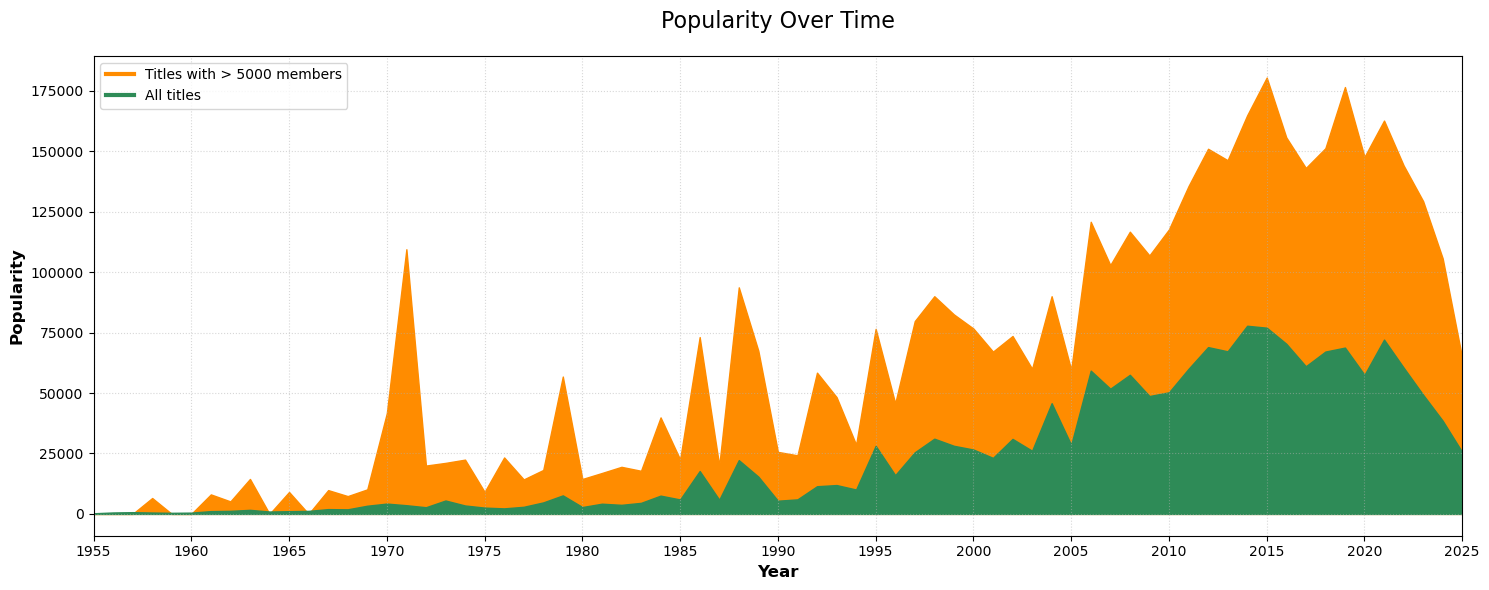

In [7]:
# preparazione dati tramite funzione
details_copy = get_cleaned_details(details_df)
# popolarità media totale
all_members = (details_copy.groupby('year_filled')['members'].mean().reindex(range(1955, 2026), fill_value=0).reset_index().rename(columns={'year_filled': 'year', 'members': 'avg_members'}))
# popolarità media filtata
filtered_members = details_copy[details_copy['members'] > 5000]
filtered_members = (filtered_members.groupby('year_filled')['members'].mean().reindex(range(1955, 2026), fill_value=0).reset_index().rename(columns={'year_filled': 'year', 'members': 'avg_members'}))
# creazione grafico
plt.figure(figsize=(15, 6))
plt.grid(linestyle=':', alpha=0.5)
# popolarità media filtrata
plt.plot(filtered_members['year'],filtered_members['avg_members'],color='darkorange',linewidth=0,label='Titles with > 5000 members')
plt.fill_between(filtered_members['year'],filtered_members['avg_members'],color='darkorange',alpha=1)
# popolarità media totale
plt.plot(all_members['year'],all_members['avg_members'],color='seagreen',linewidth=0,label='All titles')
plt.fill_between(all_members['year'],all_members['avg_members'],color='seagreen',alpha=1)
# personalizzazione assi
plt.title('Popularity Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Popularity', fontsize=12, fontweight='bold')
plt.xlim(1955, 2025)
plt.xticks(range(1955, 2026, 5))
# legenda
leg = plt.legend()
leg.get_lines()[0].set_linewidth(3)
leg.get_lines()[1].set_linewidth(3)

plt.tight_layout()
plt.show()

Possiamo osservare come la popolarità media dei titoli sia cresciuta nel tempo. Questo aumento è infatti legato all’incremento della  
produzione: con più titoli disponibili, è più probabile che emergano serie di grande successo che alzano la popolarità complessiva.  
La *popolarità media filtrata* però non mostra una crescita costante nel tempo come la *totale*.   
Nello scorso secolo si osservano picchi più importanti e maggiori oscillazioni rispetto alla media totale. In questo periodo i titoli famosi erano pochi, quindi la media è stata influenzata fortemente dai pochi anime che hanno ottenuto grande successo, mentre i meno famosi, nonchè la maggior parte, sono stati  scartati.  

>**Analisi Complessiva**   
La popolarità filtrata evidenzia i grandi successi e i picchi legati agli anime più famosi, mentre la totale mostra un andamento più regolare. Negli anni '70-’80-'90 i pochi titoli popolari alzano la media filtrata, mentre negli anni più recenti molti titoli superano la soglia minima, rendendo il trend un po' più stabile.

### Valutazione media degli anime negli anni

Invece maggiore popolarità e maggiore produzione significano anche maggiore qualità? 
Dopo aver visto la crescita dei numeri, viene naturale chiedersi: ma la qualità è rimasta la stessa? Spesso si pensa che produrre così tanto la faccia calare, ma potrebbe essere l'esatto contrario. In questa sezione vogliamo capire se l'aumento della produzione coincide effettivamente con un aumento del gradimento da parte del pubblico.
- Il grafico mostra la valutazione media degli anime per anno di uscita, per tutti i titoli e per quelli più conosciuti

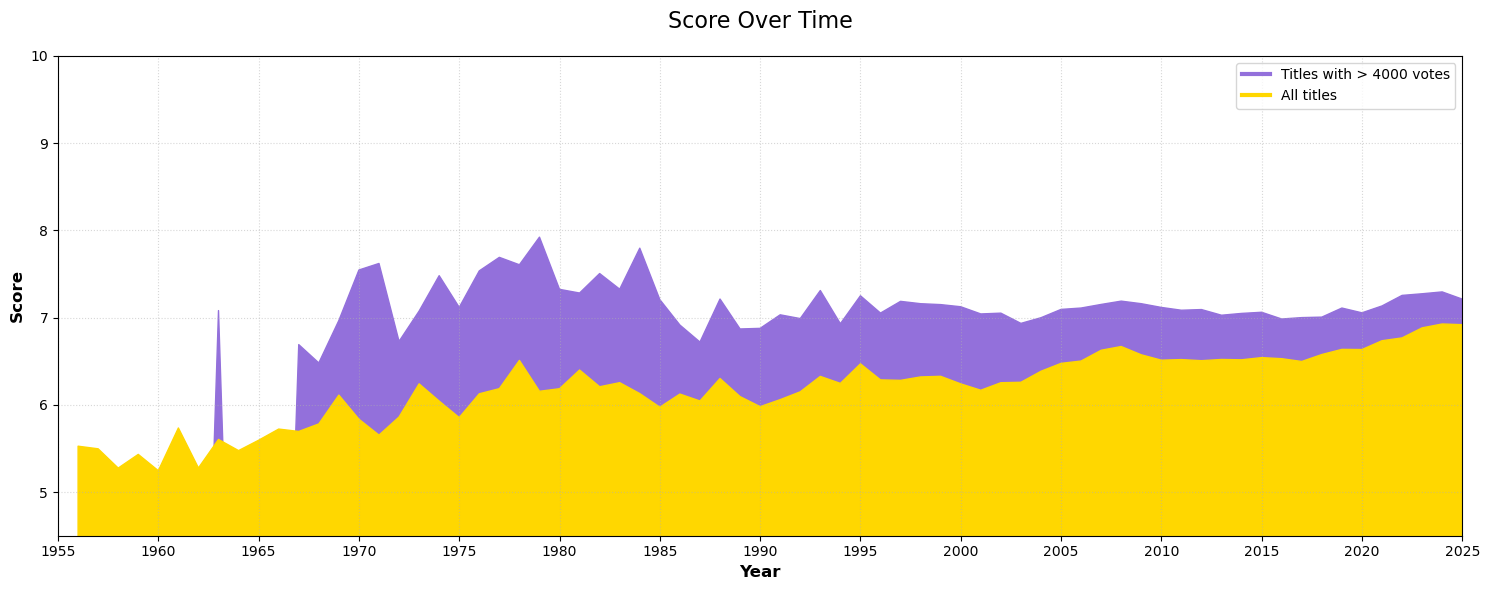

In [8]:
# preparazione dati tramite funzione
details_copy = get_cleaned_details(details_df)
# score totale
all_scored = (details_copy.groupby('year_filled')['score'].mean().reindex(range(1955, 2026), fill_value=0).reset_index().rename(columns={'year_filled': 'year', 'score': 'avg_score'}))
# score filtrato
filtred_scored = details_copy[details_copy['scored_by'] > 4000]
filtred_scored = (filtred_scored.groupby('year_filled')['score'].mean().reindex(range(1955, 2026), fill_value=0).reset_index().rename(columns={'year_filled': 'year', 'score': 'avg_score'}))
# creazione grafico
plt.figure(figsize=(15, 6))
plt.grid(linestyle=':', alpha=0.5)
# area filtrata
plt.plot(filtred_scored['year'],filtred_scored['avg_score'],color='mediumpurple',linewidth=0,label='Titles with > 4000 votes')
plt.fill_between(filtred_scored['year'],filtred_scored['avg_score'],color='mediumpurple',alpha=1)
# area totale
plt.plot(all_scored['year'],all_scored['avg_score'],color='gold',linewidth=0,label='All titles')
plt.fill_between(all_scored['year'],all_scored['avg_score'],color='gold',alpha=1)
# personalizzazione assi
plt.xticks(range(1955, 2026, 5))
plt.title(f'Score Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Score', fontsize=12, fontweight='bold')
plt.ylim(4.5, 10)
plt.xlim(1955, 2025)
# legenda
leg = plt.legend()
leg.get_lines()[0].set_linewidth(3)
leg.get_lines()[1].set_linewidth(3)

plt.tight_layout()
plt.show()

Possiamo osservare come cambia la distribuzione:  
La **valutazione media** per anno rimane abbastanza stabile, con una moderata crescita nel tempo. Questo differisce un poco dalla popolarità totale, che ha mostrato un aumento più rapido.  
La **valutazione media dei titoli più conosciuti** mostra più picchi negli anni passati, mentre oggi risultano più stabile. I picchi del passato erano causati da pochi titoli, ma generalmente con valutazioni molto alte. Possiamo notare dei buchi prima degli anni'70, questo è dovuto all'esenza di titoli che superano la soglia minima e non da una valutazione media insufficiente. 

>**Analisi Complessiva**  
La valutazione media totale mostra un andamento stabile nel tempo, con una lieve crescita che riflette un miglioramento complessivo della  
qualità delle produzioni moderne.  
La valutazione media dei titoli più conosciuti, invece, presenta più oscillazioni e picchi negli anni passati. Questo è dato dai pochi  
anime prodotti in quegli anni.  
Negli anni recenti, con un numero maggiore di titoli popolari, sia la valutazione totale sia quella filtrata risultano stabili.  
Da quanto visto possiamo dire che mediamente nel passato si producevano pochi titoli, ma solo i più popolari risultavano ben valutati, mentre ora nonostante il grosso numero di produzioni, la media si tiene alta.

### Evoluzione annuale del numero medio di episodi

Oltre alla qualità e alla popolarità, c'è un'altra cosa interessante da guardare: la durata delle serie anime. Siamo passati dai "classici" infiniti che duravano anni alle moderne stagioni più brevi.
- Il grafico mostra l’andamento della produzione anime annuale.  
- Sono inclusi esclusivamente gli anime di tipo `TV` e `ONA`, in quanto l’analisi si concentra sull’evoluzione delle serie.   
- Sono stati presi in considerazione solo i titoli con stato `Finished Airing`, per garantire una maggiore accuratezza dei dati.  
- Per gli anni con un numero ridotto di titoli, è stato indicato il conteggio degli anime prodotti, così da evidenziare che i valori medi  
sono calcolati su un campione limitato.

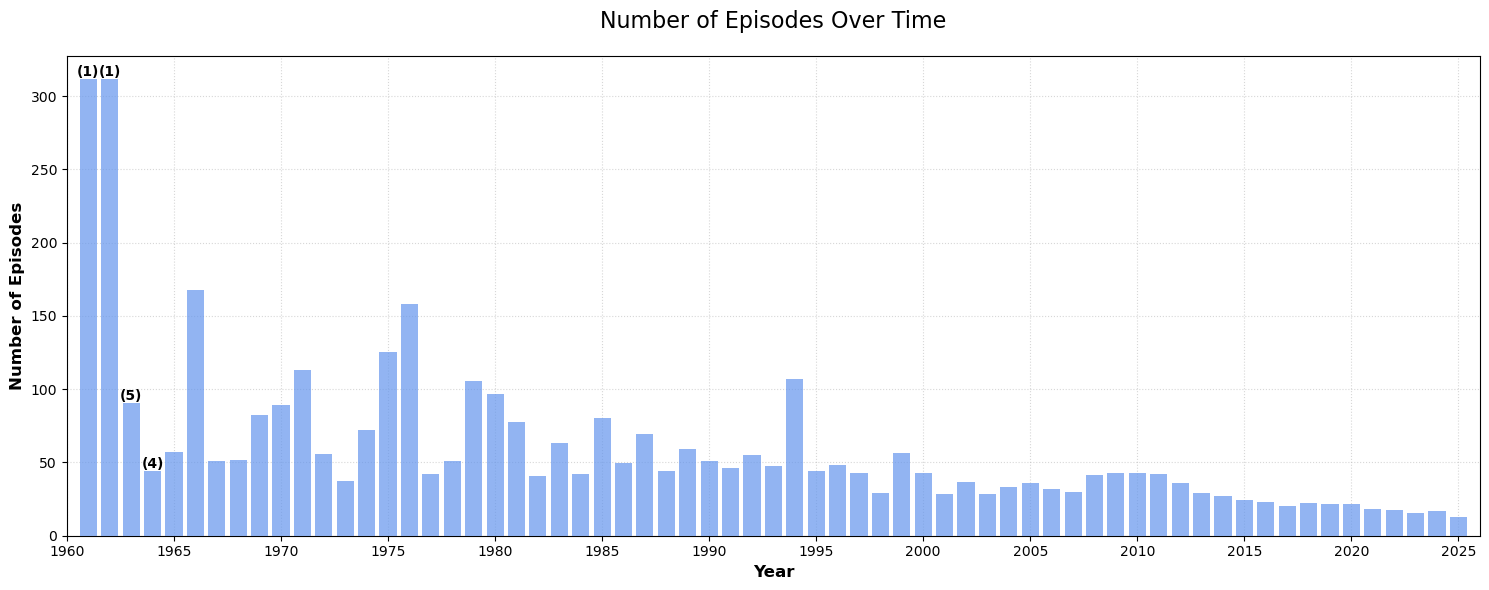

In [9]:
# preparazione dati tramite funzione
details_copy = get_cleaned_details(details_df)
# ulteriore filtraggio: solo type TV e ONA e status Finished Airing
details_copy = details_copy[(details_copy['type'].isin(['TV', 'ONA'])) & (details_copy['status'] == 'Finished Airing')]
# medie e conteggio episodi per anno
ep_mean = details_copy.groupby('year_filled')['episodes'].agg(['mean', 'count']).reset_index()
ep_mean.columns = ['year', 'avg_episodes', 'title_count']
# creazione grafico
plt.figure(figsize=(15, 6))
plt.bar(ep_mean['year'], ep_mean['avg_episodes'], color='cornflowerblue', alpha=0.7, zorder=3)
plt.grid(linestyle=':', alpha=0.5)
# personalizzazione assi
plt.title('Number of Episodes Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Number of Episodes', fontsize=12, fontweight='bold')
plt.xlim(1960, 2026)
plt.xticks(range(1960, 2026, 5))
# segnamo dove ci sono poche serie anime
for index, row in ep_mean.iterrows():
    if row['title_count'] <= 10:
        plt.text(row['year'], row['avg_episodes'], f"({int(row['title_count'])})", 
                 ha='center', va='bottom', fontsize=10, color='black', fontweight='bold')

plt.tight_layout()
plt.show()


Dal **1960 fino alla prima metà degli anni ’90**, il numero medio di episodi per anime mostra forti oscillazioni.  
Questo andamento irregolare è in parte legato al numero ridotto di serie prodotte nei primi decenni, che rende la media molto sensibile  
alla presenza di poche serie particolarmente lunghe. In questo periodo erano infatti comuni anime con un alto numero di episodi, pensati  
per una programmazione televisiva continuativa.

A partire dalla **seconda metà dagli anni ’90** il numero medio di episodi inizia a diminuire in modo più stabile, con oscillazioni meno marcate. Le serie diventano più brevi e organizzate in stagioni.
 
Dal **2010 in poi**, la discesa del numero medio di episodi diventa ancora più evidente. Questo è dovuto anche al fatto che le serie divise in stagioni brevi sono più facili da seguire e completare, adattandosi meglio alle abitudini del pubblico.

>**Analisi Complessiva**    
Comparando questa analisi con quella della produzione annuale, si evidenzia chiaramente il passaggio da poche serie lunghe negli anni    
iniziali a produzioni più brevi, ma più numerose e diversificate. Le serie lunghe richiedono un impegno maggiore per essere seguite e   
completate, mentre il pubblico moderno tende a preferire stagioni brevi e autoconclusive.



### Evoluzione del doppiaggio negli anni

Con la globalizzazione degli anime, è aumentata anche la domanda di doppiaggi in varie lingue.  
Ma come sono aumentati questi doppiaggi nel tempo? Hanno seguito l'aumento di volume nella produzione?
- Il seguente grafico ci permette di osservare le tendenze e i cambiamenti nel corso degli anni con la possibilità di scegliere specificamente quale lingua seguire. 

In [10]:
# preparazione dati tramite funzione
details_copy = get_cleaned_details(details_df)
# impostiamo italiano come prima lingua che viene visualizzata
default_lang='Italian'
# effettuiamo i merge tra dataset person_voice_works_df e details_df modificato
anime_dub = person_voice_works_df.merge(details_copy[['mal_id', 'year_filled']], left_on='anime_mal_id', right_on='mal_id', how='left')
# escludiamo il giapponese, non serve alla nostra analisi
anime_dub = anime_dub[(anime_dub['language'].str.lower() != 'japanese')]
# raggruppiamo per anno e lingua
dub_count = anime_dub.groupby(['year_filled', 'language']).size().reset_index(name='count')
languages = sorted(dub_count['language'].unique())
# colori diversi per ogni lingua
colors = ["#FA2626", "#FFB03A", "#00CC96", "#AB63FA", "#5039FF", "#19D3F3", "#FF6792", "#C1FF7E", "#25AB54", "#FF6BE1"]
# creazione grafico interattivo
fig = go.Figure()
# crea una traccia per ogni lingua
for i, lang in enumerate(languages):
    color = colors[i % len(colors)]
    df_lang = dub_count[dub_count['language'] == lang]
    fig.add_trace(go.Scatter(x=df_lang['year_filled'],y=df_lang['count'],mode='lines+markers',name=lang,
        visible=(lang.lower() == default_lang.lower()), line=dict(color=color) ))
# generazione dei bottoni del menu a tendina
buttons = []
for i, lang in enumerate(languages):
    visible = [False] * len(languages)
    visible[i] = True
    buttons.append(dict(label=lang,method="update",args=[{"visible": visible}, {"title": f"Trend of {lang} Dubbing Over Time"}]))
# personalizazzione
active_idx = languages.index(default_lang) if default_lang in languages else 0
fig.update_layout(updatemenus=[dict(active=active_idx,buttons=buttons,x=1.15,y=1.2)], title=f"Trend of: {default_lang} Dubbing Over Time",
                    xaxis_title="Year",yaxis_title="Number of Dubbings",width=900, height=500, plot_bgcolor="#f2f2f2", 
                    yaxis=dict(range=[0, dub_count['count'].max() + 1000]) )
fig.show()

Osservando il grafico emergono diversi trend nelle varie lingue:   
Il **coreano** ha avuto il suo picco tra il 2000 e il 2010, per poi calare negli anni successivi, nonostante la disponibilità di un numero maggiore di titoli da doppiare.  
L’**ebraico** e l’**ungherese**, invece, hanno sempre avuto un numero molto limitato di doppiaggi: l’ebraico tra gli anni '90 e 2000, e l’ungherese principalmente tra il 2000 e il 2010, senza sviluppi significativi dopo questi periodi.   
Il **mandarino** ha iniziato a crescere solo dopo il 2015 e ora sembra stabilizzarsi, pur rimanendo a livelli relativamente bassi.  
>**Analisi Complessiva**
In generale nel 2025, con la produzione complessiva di anime diminuita, anche il numero totale di doppiaggi è sceso, seguendo più o meno la stessa tendenza. Le altre lingue non citate mostrano andamenti simili, confermando come la diffusione dei doppiaggi sia legata alla produzione e popolarità degli anime. 


## 2. Analisi Correlativa tra Generi e Target Demografici degli Anime

Il mondo degli anime comprende al suo interno una grande varietà di generi e target demografici.  
Analizzeremo la distribuzione di queste categorie, con l’obiettivo di comprendere quali tipologie narrative e quali pubblici di riferimento risultino maggiormente rappresentati, individuando eventuali squilibri o tendenze dominanti.

### Distribuzione dei generi 

Ora visualizziamo quanti anime appartengono a ciascun genere e come l’evoluzione dei generi cambia negli anni.
- Il primo grafico mostra la distribuzione complessiva dei generi  
- Il secondo permette di seguire il trend di ogni singolo genere nel tempo.

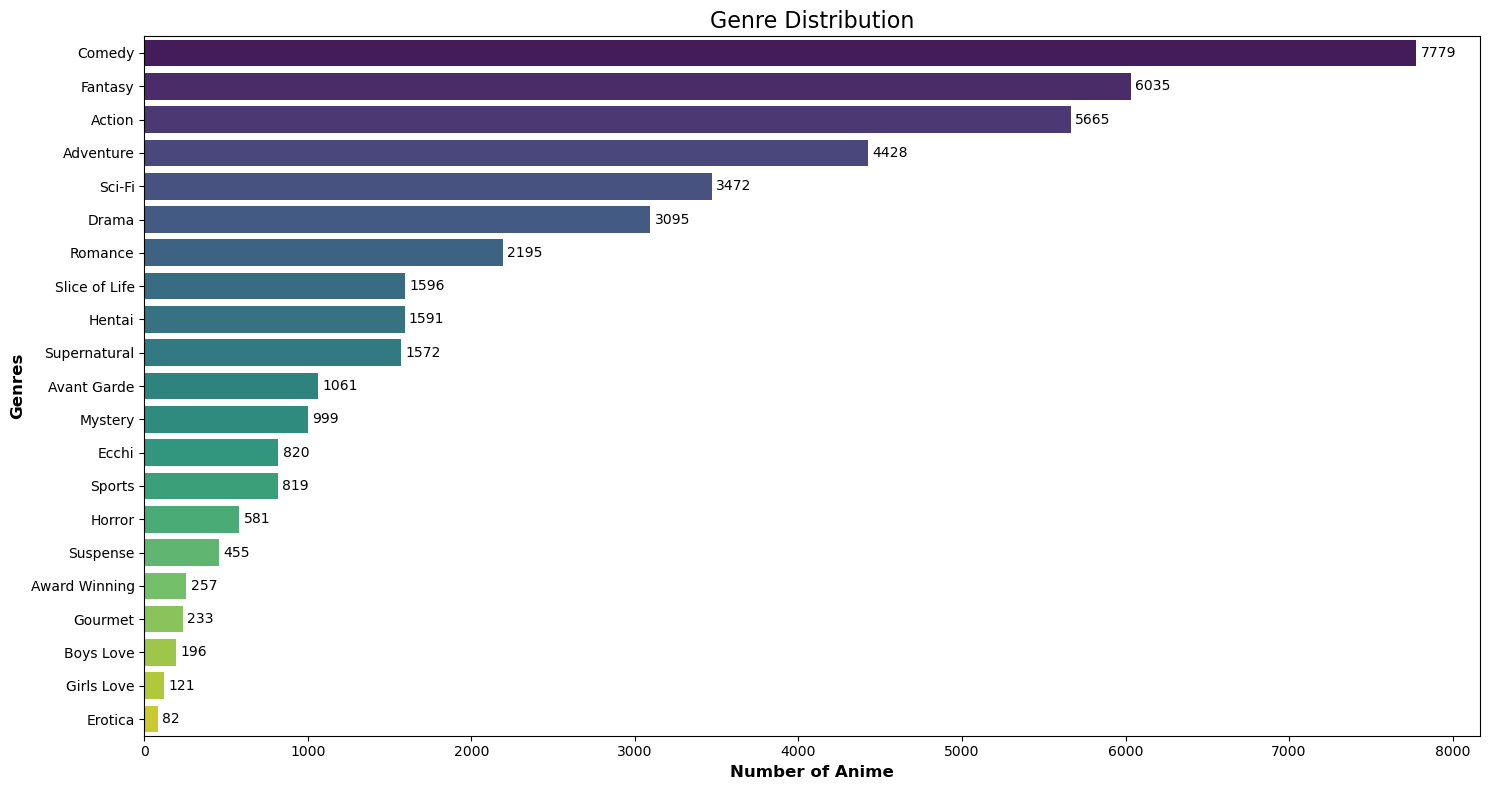

In [11]:
details_copy = details_df.copy()
# esplodiamo genres in quanto sono liste
details_copy['genres'] = details_copy['genres'].apply(eval)
details_copy = details_copy.explode('genres')
# conteggio generi totali
genre_count = details_copy['genres'].value_counts().reset_index()
genre_count.columns = ['genre', 'count']
# creazione grafico
plt.figure(figsize=(15,8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
# numero conteggi per genere
for container in ax.containers:
    ax.bar_label(container, padding=3)
# personalizzazione assi
plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
# preparazione dati tramite funzione e esplosione liste
details_copy = get_cleaned_details(details_df)
details_copy['genres'] = details_copy['genres'].apply(eval)
details_copy = details_copy.explode('genres')
# conteggio
genre_count = details_copy.groupby(['year_filled', 'genres']).size().reset_index(name='count')
genres_list = sorted(genre_count['genres'].unique())
# creazione grafico
default_genre='Action'
fig = go.Figure()
# crea una traccia per ogni genere
for genre in genres_list:
    df_genre = genre_count[genre_count['genres'] == genre]
    fig.add_trace(go.Scatter(x=df_genre['year_filled'],y=df_genre['count'], mode='lines+markers', name=genre, 
                                visible=(genre == default_genre), line=dict(color= "#19D3F3")))
# generazione dei bottoni del menu a tendina
buttons = []
for i, genre in enumerate(genres_list):
    visible = [False] * len(genres_list)
    visible[i] = True
    buttons.append(dict(label=genre, method="update", args=[{"visible": visible}, {"title": f"Trend of {genre} Anime Over Time"}]))
# personalizzazione
fig.update_layout(updatemenus=[dict(active=genres_list.index(default_genre) if default_genre in genres_list else 0, buttons=buttons, x=1.15, y=1.2)],
    title=f"Trend of {default_genre} Anime Over Time", xaxis_title="Year",yaxis_title="Number of Anime",width=900,height=500, 
    plot_bgcolor="#f2f2f2", yaxis=dict(range=[0, 400]))
fig.show()

Possiamo osservare che il genere Comedy risulta il più prodotto in assoluto, questo perchè è un genere "universale" che riesce ad alleggerire qualsiasi storia e si mescola molto bene con tutto il resto dei generi, dal romance all'azione pura.  
Negli ultimi anni, tuttavia, si nota una crescita significativa del genere Fantasy, arrivando a dominare la scena. Ciò riflette anche il bisogno di evasione degli spettatori, che preferiscono immergersi in mondi diversi dove tutto è possibile.

>**Analisi Complessiva**  
È difficile che un anime appartenga a una sola categoria. Spesso la Comedy fa da base, ma si intreccia con molti altri stili narrativi.  
Dato che molti anime si rivolgono a un pubblico giovane, il tono 'scherzoso' viene usato come "comic relief" per bilanciare i momenti più drammatici o i combattimenti intensi, evitando che la storia diventi troppo pesante.

---
Ma quale sono invece i generi prediletti dai i top 10 studios di produzione?   
L'heatmap proposto ci permette di visualizzare la densità di produzione per ogni studio.

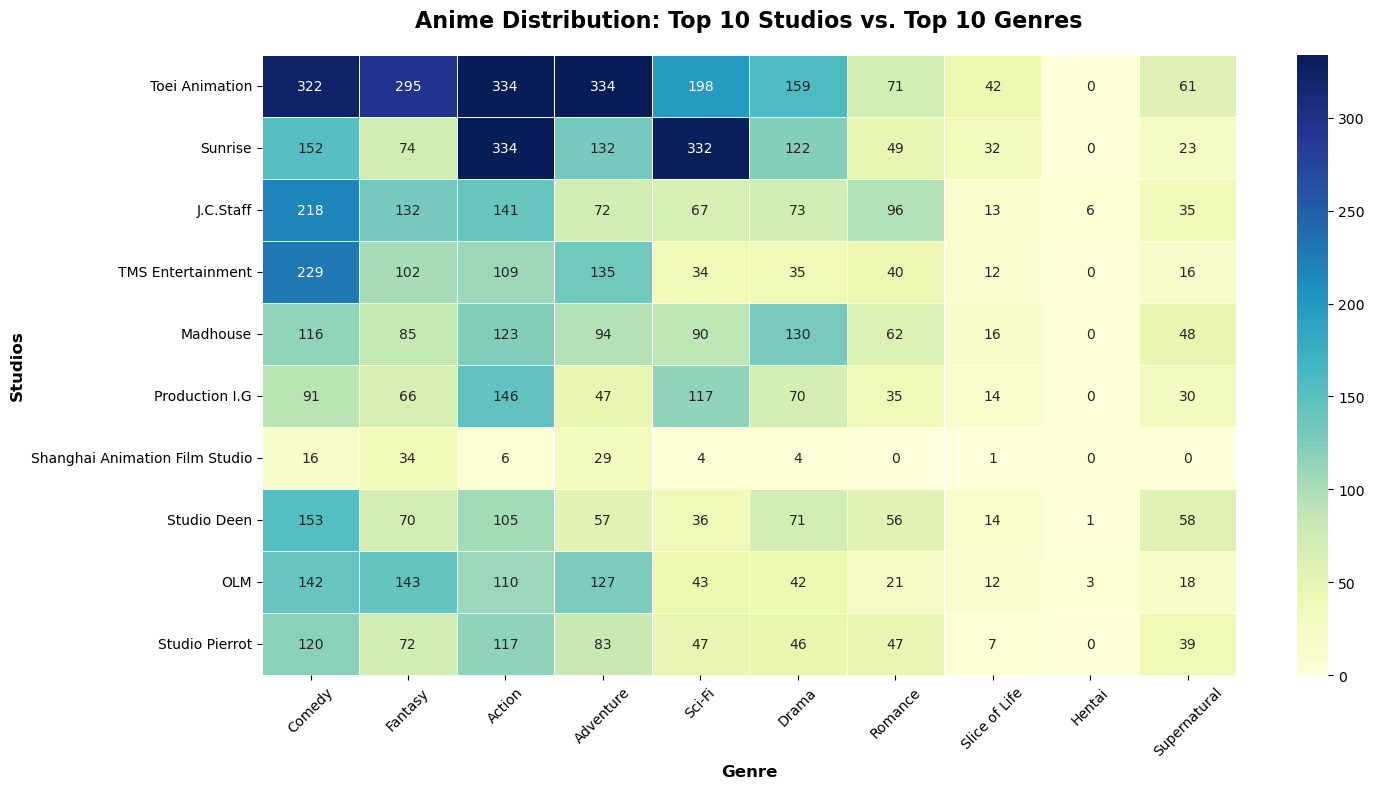

In [13]:
# creo copia di details
details_copy = details_df.copy()
# esplodiamo studios e generi
details_copy['genres'] = details_copy['genres'].apply(eval)
details_copy['studios'] = details_copy['studios'].apply(eval)
# individuo top 10 studios e generi
top_10_genres = details_copy['genres'].explode().value_counts().nlargest(10).index.tolist()
top_10_studios = details_copy['studios'].explode().value_counts().nlargest(10).index.tolist()
details_copy = details_copy.explode('genres').explode('studios')
details_copy = details_copy[details_copy['genres'].isin(top_10_genres) & details_copy['studios'].isin(top_10_studios)]
# creazione heatmap
heatmap_data = details_copy.pivot_table(index='studios', columns='genres', values='mal_id', aggfunc='nunique', fill_value=0)
heatmap_data = heatmap_data.reindex(index=top_10_studios, columns=top_10_genres)
plt.figure(figsize=(15, 8))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap='YlGnBu', linewidths=.5)
# personalizzazione assi
plt.title('Anime Distribution: Top 10 Studios vs. Top 10 Genres', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Genre', fontsize=12, fontweight='bold')
plt.ylabel('Studios', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

>**Analisi Complessiva**  
In generale, gli studios più importanti sembrano preferire anime di genere *Action* e *Comedy*. Si osserva una maggiore densità di produzione nei generi più popolari, mentre i generi che occupano le posizioni più basse della top 10 mostrano volumi sensibilmente ridotti.

### Distribuzione delle demografiche

Il grafico a torta mostra la suddivisione della demografica, ovvero il target specifico a cui gli anime si rivolgono.  
Per chi non è esperto di anime, questi termini giapponesi indicano le fasce d'età e il genere del pubblico di riferimento:
- **Shounen**: Sono gli anime pensati principalmente per i ragazzi adolescenti
- **Seinen**: Si rivolgono a un pubblico maschile più grande e adulto. 
- **Shoujo**: Sono rivolti a un pubblico femminile adolescente.
- **Josei**: Come i Seinen sono rivolti a un pubblico più adulto, ma femminile. 

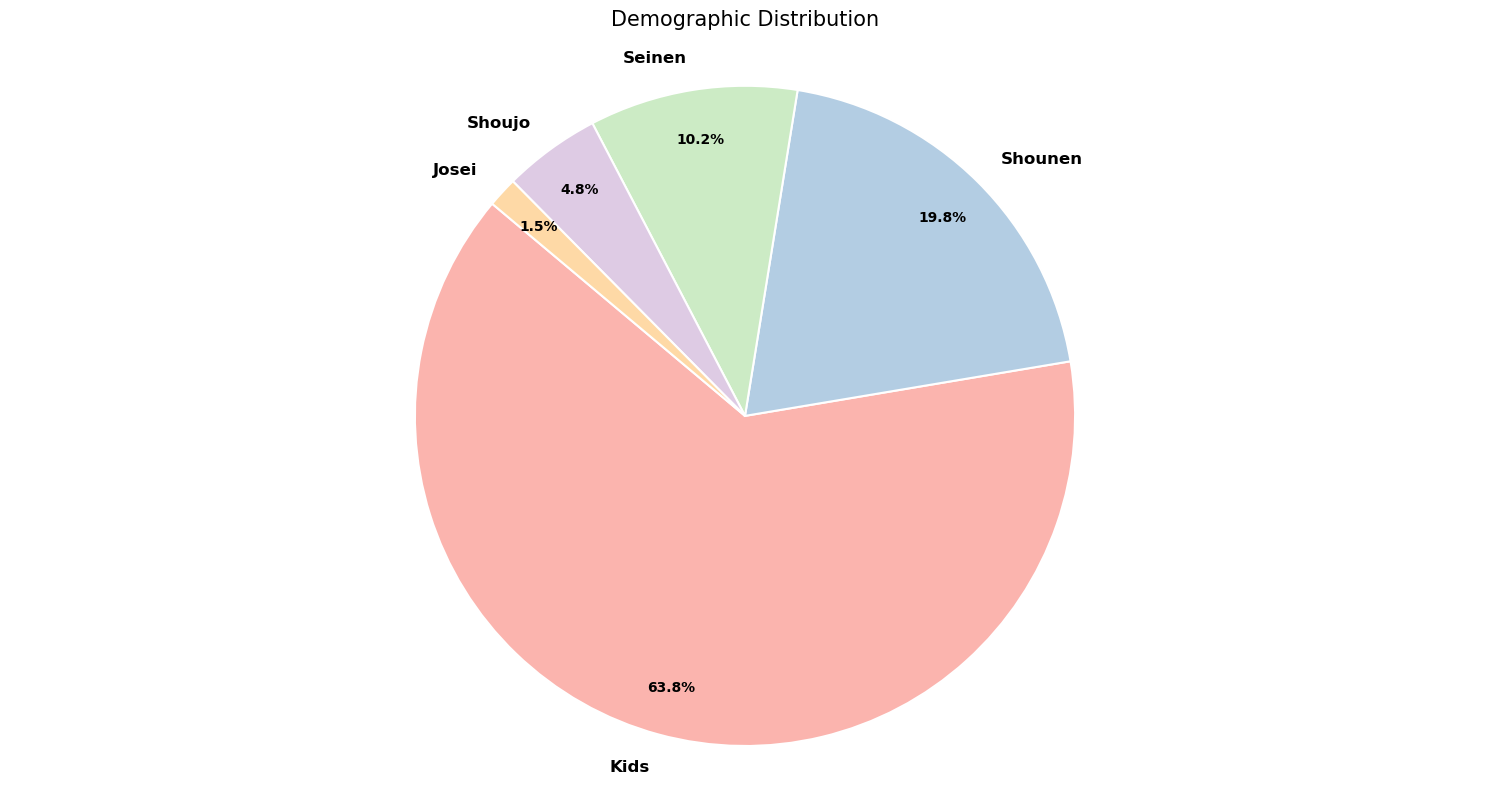

In [14]:
details_copy = details_df.copy()
# esplodiamo le demografiche
details_copy = details_copy['demographics'].apply(eval).explode()
demographic_count = details_copy.value_counts()
# creazione grafico a torta
colors = plt.cm.Pastel1(range(len(demographic_count)))
fig, ax = plt.subplots(figsize=(15, 8)) 
wedges, texts, autotexts = ax.pie(
    demographic_count,
    labels=demographic_count.index,
    autopct='%1.1f%%',    
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    pctdistance=0.85 
)
plt.setp(autotexts, size=10, weight="bold", color="black")
plt.setp(texts, size=12, weight="bold")
ax.set_title('Demographic Distribution', fontsize=15, pad=20)
plt.axis('equal') 
plt.tight_layout()
plt.show()

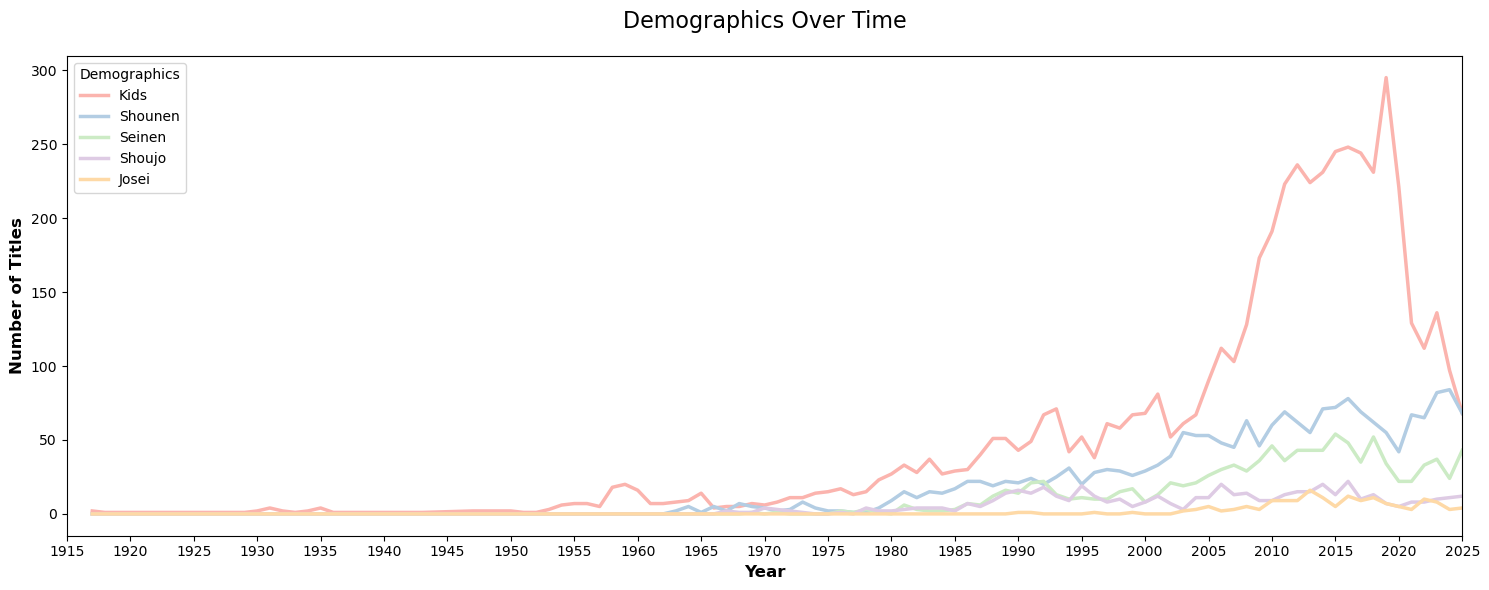

In [15]:
details_copy = get_cleaned_details(details_df)
details_copy = details_copy[details_copy['year_filled'] < 2026].copy()
details_copy['demographics'] = details_copy['demographics'].apply(eval)
details_copy = details_copy.explode('demographics')
# conteggio per anno
counts = details_copy.groupby(['year_filled', 'demographics']).size().unstack(fill_value=0).sort_index()
# per tenere gli stessi colori del pie chart
freq_order = details_copy['demographics'].value_counts().index
counts = counts[freq_order]
n_colors = len(counts.columns)
palette = plt.cm.Pastel1(range(n_colors))
# creazione grafico
plt.figure(figsize=(15,6))
plt.grid(linestyle=':', alpha=0.5)
counts.plot(kind='line', ax=plt.gca(), linewidth=2.5, color=palette)
# personalizzazione assi
plt.title(f'Demographics Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.legend(title='Demographics', loc='upper left', frameon=True)
plt.xlim(1915, 2025)
plt.xticks(ticks=range(1915, 2026, 5))

plt.tight_layout()
plt.show()


>**Analisi Complessiva**  
La maggior parte degli anime è indirizzata ai bambini (Target Kid), una categoria che ha predominato costantemente nel corso degli anni. 
È a partire dagli anni '80, con l'uscita di serie più mature e complesse, che si è vista una crescita costante anche per gli altri target.
Se però analizziamo i dati escludendo gli anime per bambini, è chiaro che l'industria sembra preferire il pubblico maschile. La percentuale di Josei è estremamente bassa, probabilmente legato al fatto che le donne adulte siano meno propense a consumare anime rispetto ad altri tipi di media, come i live-action drama.

### Generi dominanti per target

Questi grafici mettono in evidenza i top 3 generi per ogni target, offrendoci una panoramica chiara su come cambiano i generi degli anime  
in base alla demografica a cui sono rivolti.

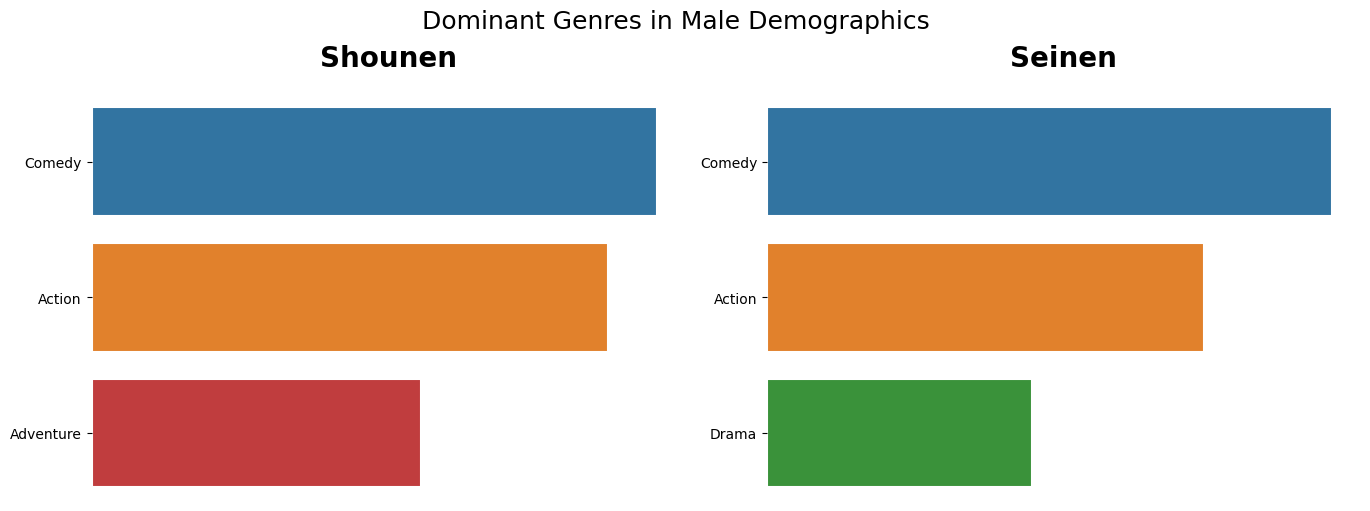

In [16]:
# funzione che esplode generi e demografiche
details_copy = get_exploded(details_df)
# target maschili
target_order = ['Shounen', 'Seinen']
details_copy = details_copy[details_copy['demographics'].isin(target_order)]
# conteggio
genre_count_male = details_copy.groupby(['demographics', 'genres']).size().reset_index(name='count')
genre_count_male = genre_count_male.sort_values(['demographics', 'count'], ascending=[True, False]).groupby('demographics').head(3)
# creazione grafico
g = sns.catplot(data=genre_count_male, kind="bar", y="genres", x="count", col="demographics", col_order=target_order, hue="genres", 
    palette="tab10", sharey=False, sharex=False, height=5, aspect=1.4, dodge=False, edgecolor='white', linewidth=1.5)
g.set_axis_labels("", "")
g.set(xticks=[])
g.set_titles("{col_name}", size=20, fontweight='bold', pad=20)
g.despine(left=True, bottom=True)
g.fig.suptitle('Dominant Genres in Male Demographics', fontsize=18, y=1.1)
plt.show()

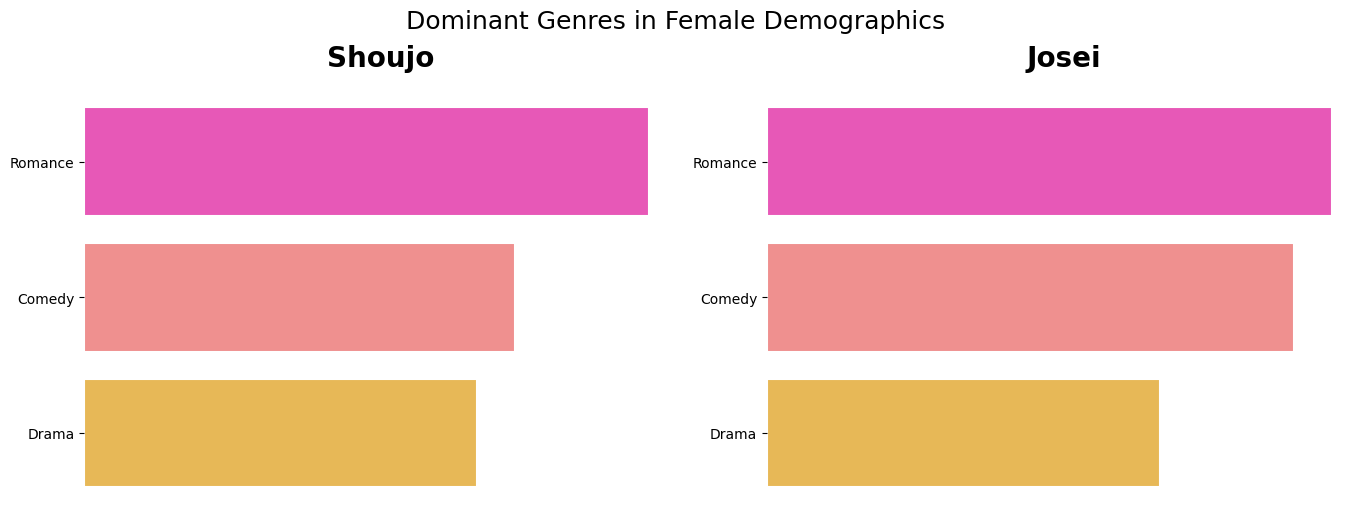

In [17]:
# funzione che esplode generi e demografiche
details_copy = get_exploded(details_df)
# target femminili
target_order = ['Shoujo', 'Josei']
details_copy = details_copy[details_copy['demographics'].isin(target_order)]
# conteggio
genre_count_female = details_copy.groupby(['demographics', 'genres']).size().reset_index(name='count')
genre_count_female = genre_count_female.sort_values(['demographics', 'count'], ascending=[True, False]).groupby('demographics').head(3)
# creazione grafico
g = sns.catplot(data=genre_count_female, kind="bar", y="genres", x="count", col="demographics", col_order=target_order, hue="genres", 
    palette="spring", sharey=False, sharex=False, height=5, aspect=1.4, dodge=False, edgecolor='white', linewidth=1.5)
g.set_axis_labels("", "")
g.set(xticks=[])
g.set_titles("{col_name}", size=20, fontweight='bold', pad=20)
g.despine(left=True, bottom=True)
g.fig.suptitle('Dominant Genres in Female Demographics', fontsize=18, y=1.1)
plt.show()

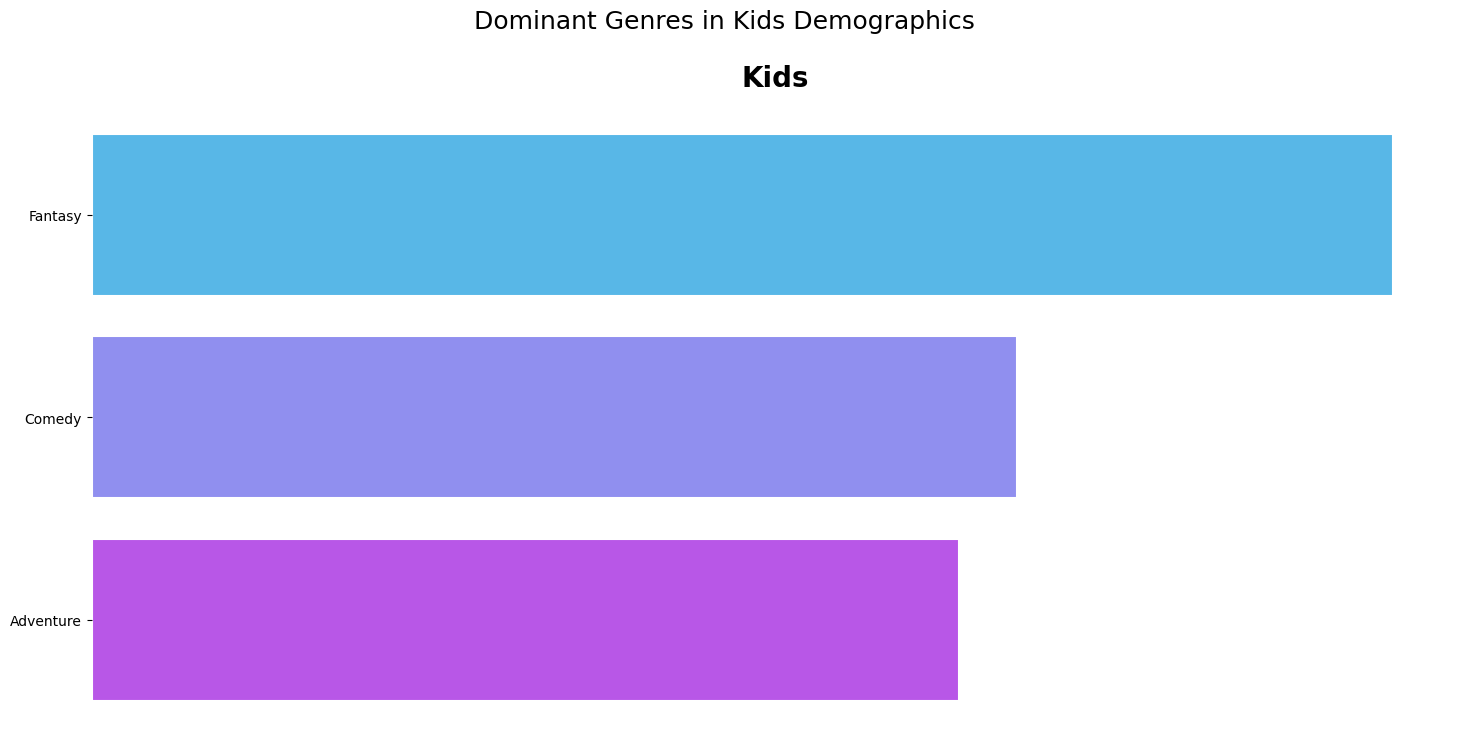

In [18]:
# funzione che esplode generi e demografiche
details_copy = get_exploded(details_df)
# target kids
target = ['Kids']
details_copy = details_copy[details_copy['demographics'].isin(target)]
# conteggio
genre_count_kids = details_copy.groupby(['demographics', 'genres']).size().reset_index(name='count')
genre_count_kids = genre_count_kids.sort_values(['demographics', 'count'], ascending=[True, False]).groupby('demographics').head(3)
# creazione grafico
g = sns.catplot(data=genre_count_kids, kind="bar", y="genres", x="count", col="demographics", hue="genres", 
    palette="cool", sharey=False, sharex=False, height=7, aspect=2.14, dodge=False, edgecolor='white', linewidth=1.5)
g.set_axis_labels("", "")
g.set(xticks=[])
g.set_titles("{col_name}", size=20, fontweight='bold', pad=20)
g.despine(left=True, bottom=True)
g.fig.suptitle('Dominant Genres in Kids Demographics', fontsize=18, y=1.1)
plt.show()

Il genere Comedy, come abbiamo visto, rientra praticamente sempre nella top 3: questo succede perché è un genere estremamente flessibile, capace di mescolarsi bene con qualsiasi altra tematica.  
Se guardiamo i dati, le preferenze tendono a rimanere piuttosto simili in base al sesso.

- Per quanto riguarda gli **maschi**, nei Seinen si nota una preferenza nella produzione di Drama rispetto alle avventure. Probabilmente perché in età adulta si cercano storie più profonde. Nonostante questo, come per gli Shonen, i pilastri rimangono la Comedy e l'Action.

- Per le **femmine**, invece, la situazione è molto costante in entrambe le demografiche: il genere top assoluto rimane il Romance, seguito poi dalla Comedy e dal Drama. 

- Gli anime per **bambini** sembrano essere quelli che trainano maggiormente il genere Fantasy. 

### Valutazione media per genere

Questo grafico ci dà una visuale chiara su quali generi ottengono mediamente i punteggi più alti.

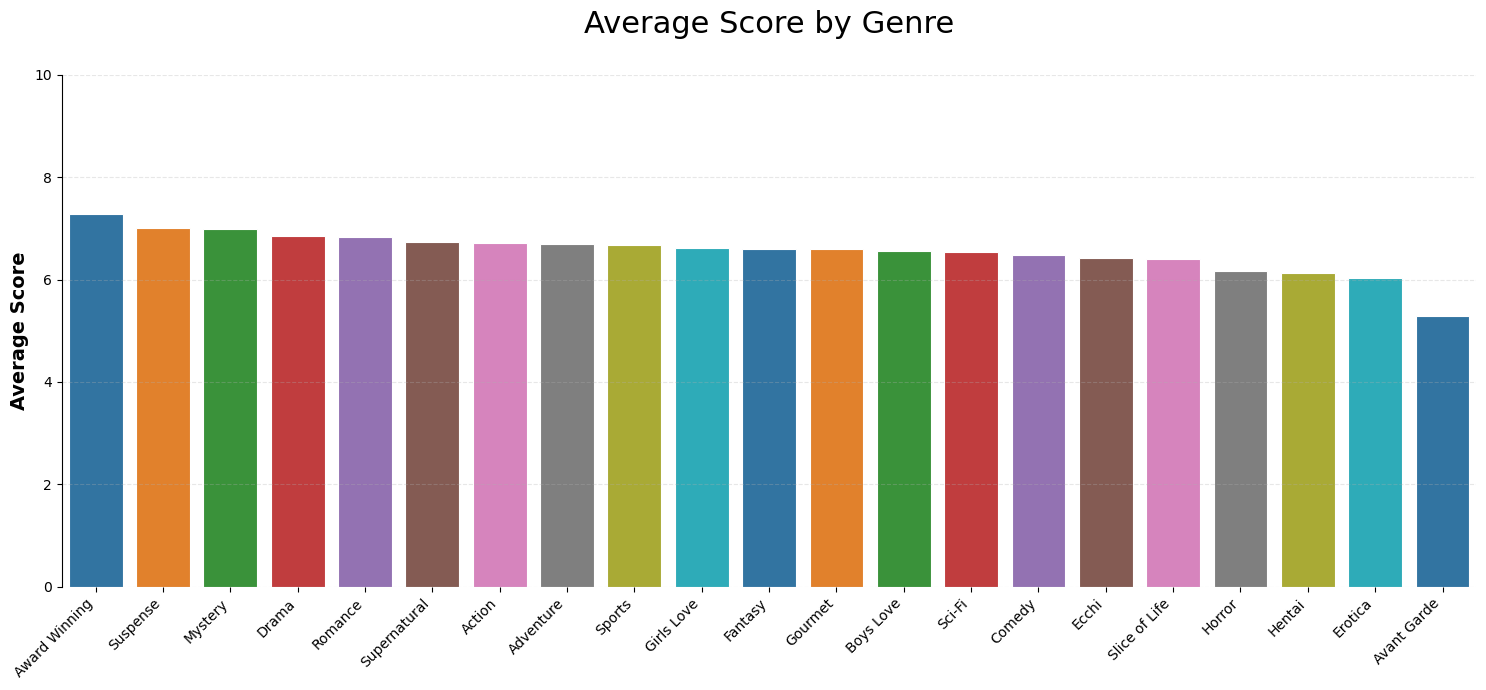

In [19]:
details_copy = details_df.copy()
# esplodiamo generi
details_copy['genres'] = details_copy['genres'].apply(eval)
details_copy = details_copy.explode('genres')
# media dei voti
avg_score = details_copy.groupby('genres')['score'].mean().reset_index()
avg_score = avg_score.sort_values('score', ascending=False)
# creazione grafico
plt.figure(figsize=(15, 7)) 
sns.barplot(data=avg_score, x='genres', y='score', hue='genres', palette='tab10', edgecolor='white', linewidth=0.8)
plt.title('Average Score by Genre', fontsize=22, pad=30)
plt.xlabel("")
plt.ylabel("Average Score", fontsize=14, fontweight='bold')
plt.ylim(0, 10) 
plt.xticks(rotation=45, ha='right', fontsize=10)
sns.despine(bottom=True)
plt.grid(axis='y', linestyle='--', alpha=0.3) 
plt.tight_layout()
plt.show()

>**Analisi Complessiva**  
Non sorprende che *Award Winning* presenti la media voto più alta in assoluto. In questa categoria rientrano opere che hanno ottenenuto  
riconoscimenti per la regia e la sceneggiatura. Sono titoli che partono già con un'altissima aspettativa che, quasi sempre, viene  
confermata dal voto finale degli utenti.   
Stranamente, a differenza di quanto si possa pensare, il genere *Avant-Garde* presenta la media voti più bassa di tutte. Queste opere nascono per  
essere sperimentali. Spesso sono storie che risultano difficili per lo spettatore medio; sono prodotti che di solito o si amano o si odiano.

### Densità dei Personaggi per Genere e Target

Esamineremo come la numerosità del cast vari in base al genere e al target di riferimento.  
L'obiettivo è identificare quali categorie richiedano un numero maggiore di personaggi per sostenere la narrazione.

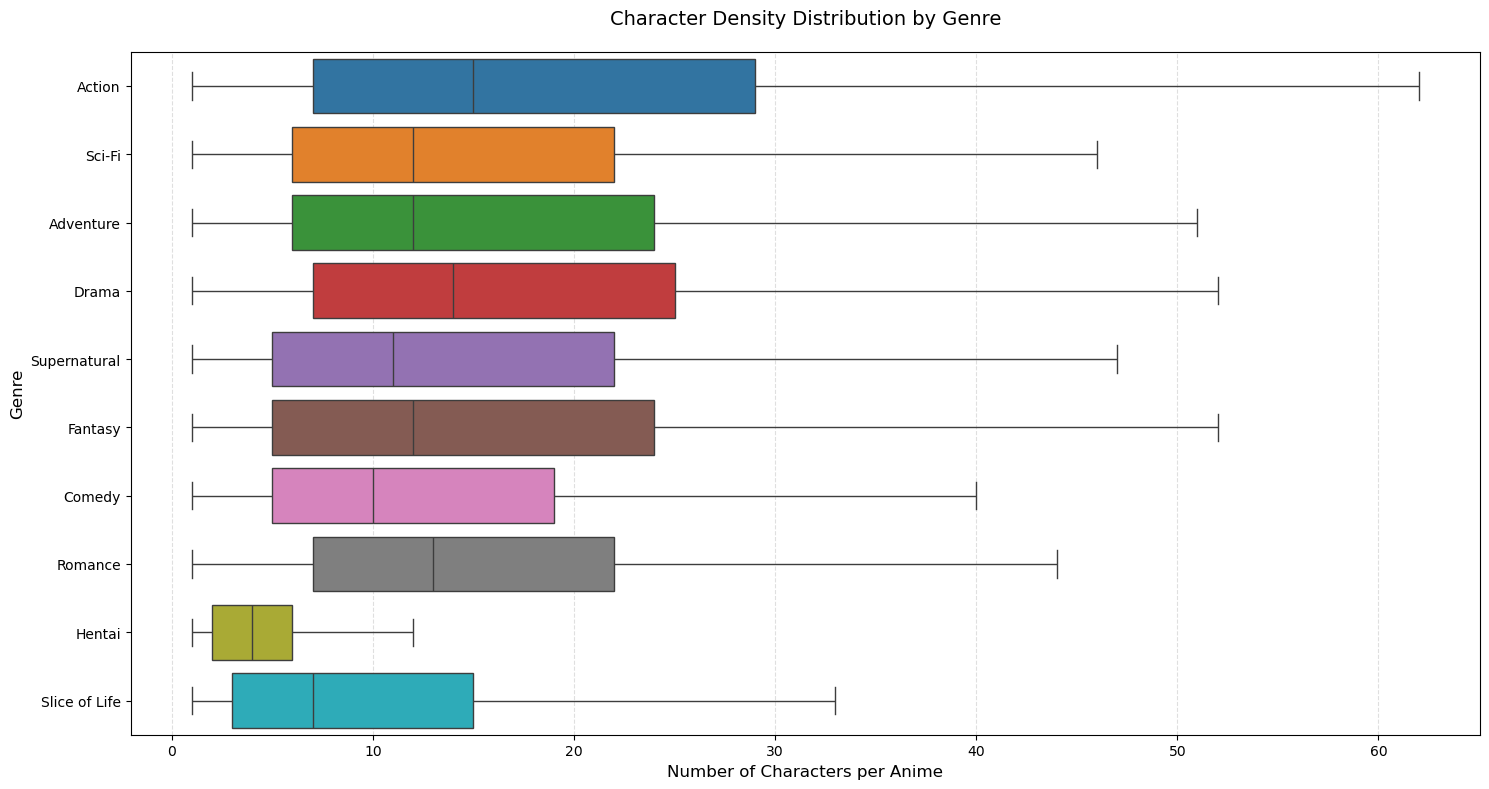

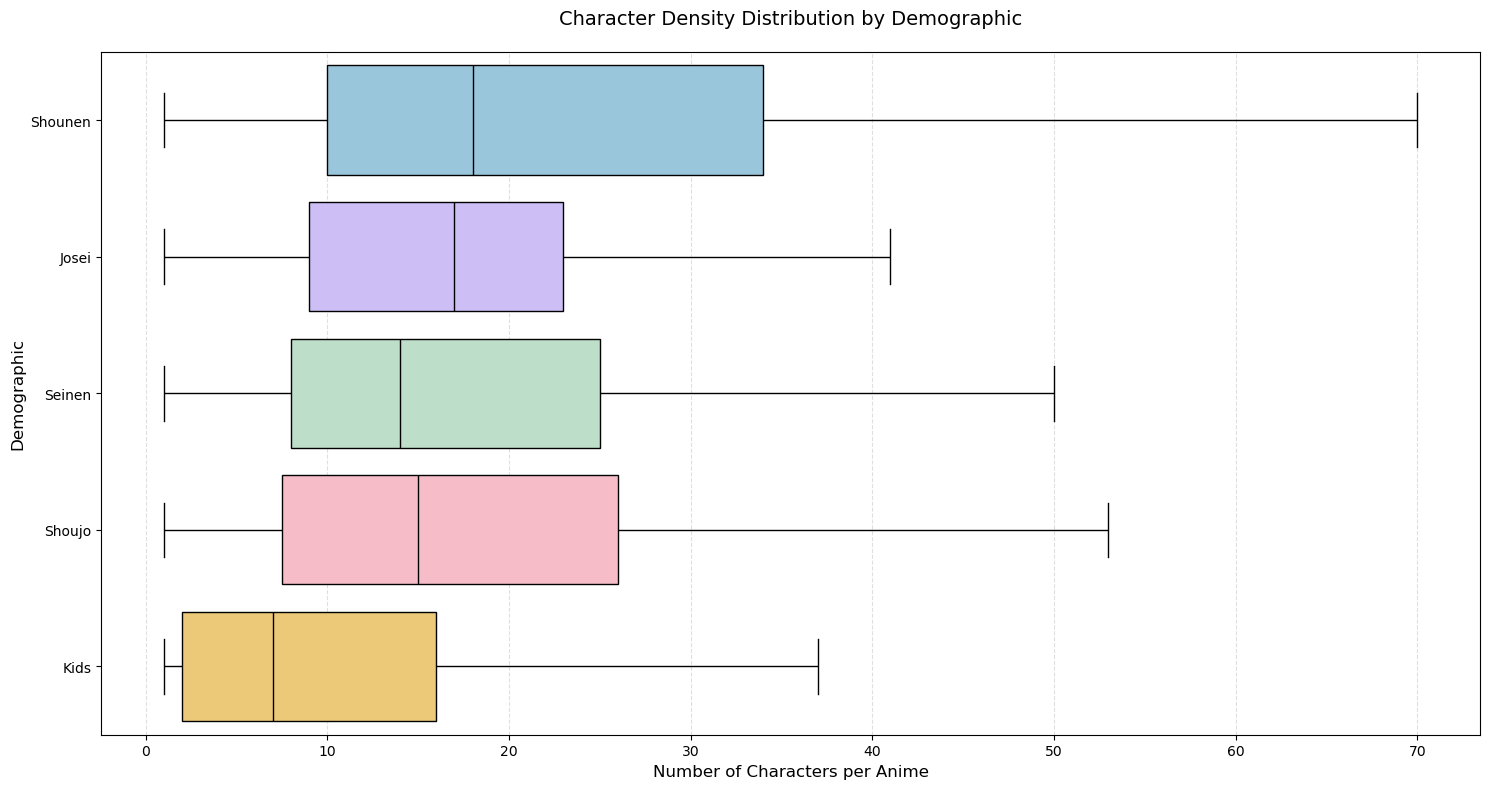

In [20]:
details_copy = details_df.copy()
caw_copy = character_anime_works_df.copy()
# conteggio personaggi
char_counts = caw_copy.groupby('anime_mal_id').size().reset_index(name='char_count')
char_counts.rename(columns={'anime_mal_id': 'mal_id'}, inplace=True)
# merge con demografiche e generi
merged = pd.merge(char_counts, details_df[['mal_id', 'genres', 'demographics']], on='mal_id')
merged = get_exploded(merged).reset_index(drop=True)
top_10_genres = merged['genres'].value_counts().nlargest(10).index
char_genres = merged[merged['genres'].isin(top_10_genres)]
# creazione grafico per genere
plt.figure(figsize=(15, 8))
plt.grid(axis='x', linestyle='--', alpha=0.4)
sns.boxplot(data=char_genres, x='char_count', y='genres', hue='genres',palette='tab10', orient='h', showfliers=False) 
plt.title('Character Density Distribution by Genre', fontsize=14, pad=20)
plt.xlabel('Number of Characters per Anime', fontsize=12)
plt.ylabel('Genre', fontsize=12)

plt.tight_layout()
plt.show()
# creazione grafico per demografica
palette = {'Shounen': '#8ecae6','Seinen': '#b7e4c7','Shoujo': '#ffb3c1','Josei': '#c8b6ff','Kids': '#ffd166'}
plt.figure(figsize=(15, 8))
plt.grid(axis='x', linestyle='--', alpha=0.4)
sns.boxplot(data=merged, x='char_count', y='demographics', hue='demographics', palette=palette, orient='h', 
            showfliers=False, linecolor='black', legend=False)
plt.title('Character Density Distribution by Demographic', fontsize=14, pad=20)
plt.xlabel('Number of Characters per Anime', fontsize=12)
plt.ylabel('Demographic', fontsize=12)

plt.tight_layout()
plt.show()

>**Analisi Complessiva**  
La numerosità del cast è una risposta diretta alle esigenze narrative.  
A livello di genere, l'*Action* domina: la costruzione di mondi vasti e battaglie richiede la creazione di molti personaggi.  
Al contrario, lo *Slice of Life* mostra un cast ridotto per un approfondimento più intimo, mentre i titoli *Hentai* riducono il cast all'essenziale per ovvie ragioni.  
Questa gerarchia si riflette nelle demografiche, dove lo *Shounen* svetta per densità media dei personaggi. Ciò è dovuto anche alla forte sovrapposizione con il genere *Action* e alla dinamicità delle sue saghe. 
All'opposto, il target *Kids* presenta i cast più ristretti poichè hanno una narrazione semplice e immediata.

## 3. Indagine sugli Utenti

Il vero motore trainante dell'universo anime sono i fan. In questa sezione, analizzeremo le preferenze reali degli utenti che guardano e  
valutano i titoli presenti nel dataset, spostando l'attenzione dal prodotto a chi lo consuma.  
L'obiettivo è scoprire cosa interessa davvero all'audience, individuando trend attraverso la suddivisione dei dati per genere, fascia  
d'età e paese di provenienza.

### Distribuzione dei generi degli utenti

Il grafico mostra la ripartizione degli utenti in base al sesso dichiarato nel profilo (Male, Female, Non-Binary).

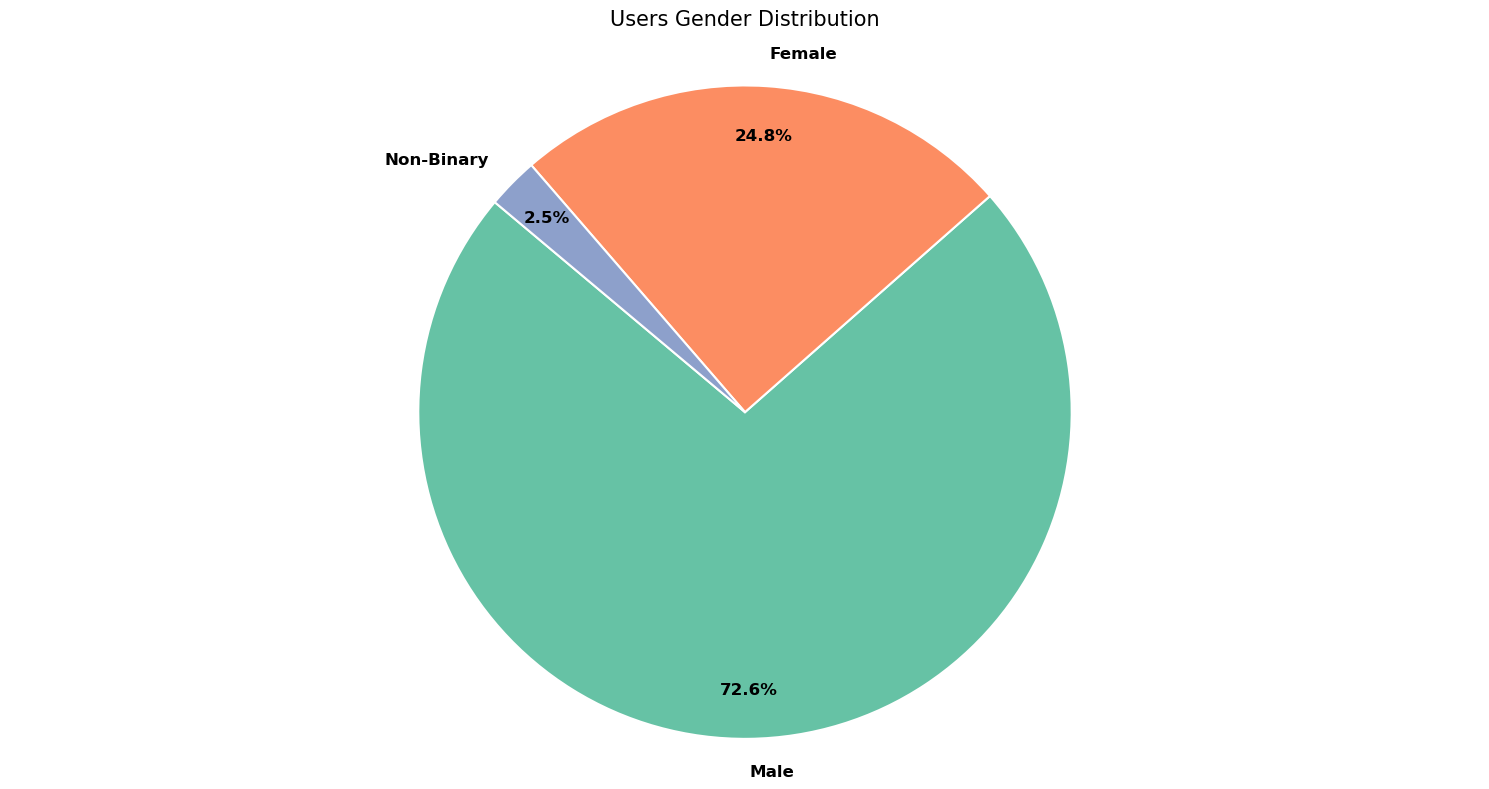

In [21]:
profiles_copy = profiles_df.copy()
# conteggio per genere
count_gender = profiles_copy['gender'].value_counts()
colors = plt.cm.Set2(range(len(profiles_copy)))
# creazione grafico a torta
fig, ax = plt.subplots(figsize=(15, 8)) 
wedges, texts, autotexts = plt.pie(count_gender,labels=count_gender.index,autopct='%1.1f%%',startangle=140, 
                                wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}, pctdistance=0.85, colors=colors)

plt.setp(autotexts, size=12, weight="bold", color="black")
plt.setp(texts, size=12, weight="bold")
ax.set_title('Users Gender Distribution', fontsize=15, pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()

Le piattaforme di catalogazione anime mostrano una partecipazione maschile superiore, superando il 70% del totale degli utenti.



---
Abbiamo visualizzato precedentemente quali sono i generi dominanti per ogni target, ma rispecchierà davvero le preferenze degli utenti?  
Per rispondere a questa domanda, esploriamo i 10 generi più visti, prendendo in considerazione solo anime con status completed e watching,  
segmentati per il sesso dichiarato degli utenti.

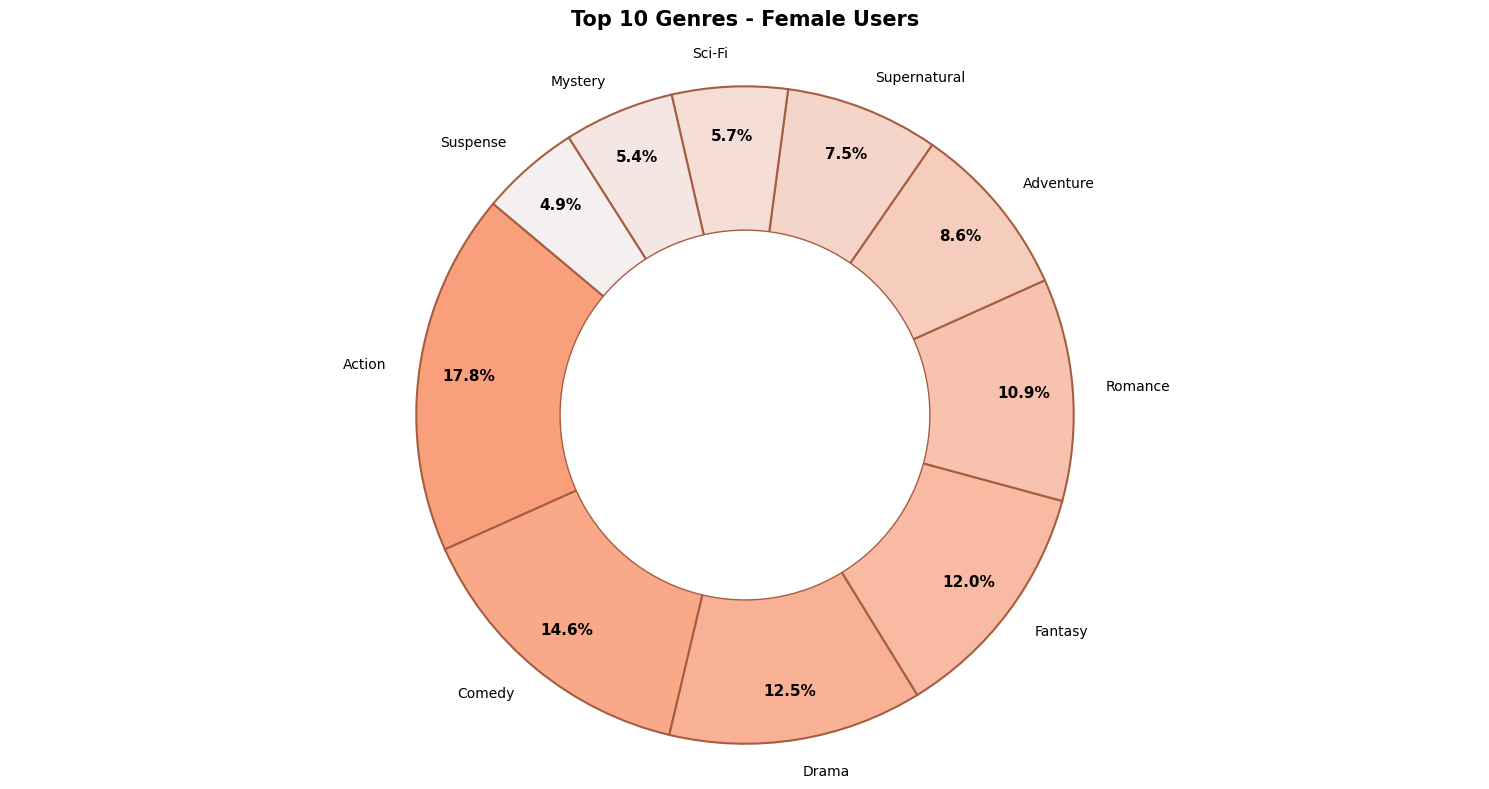

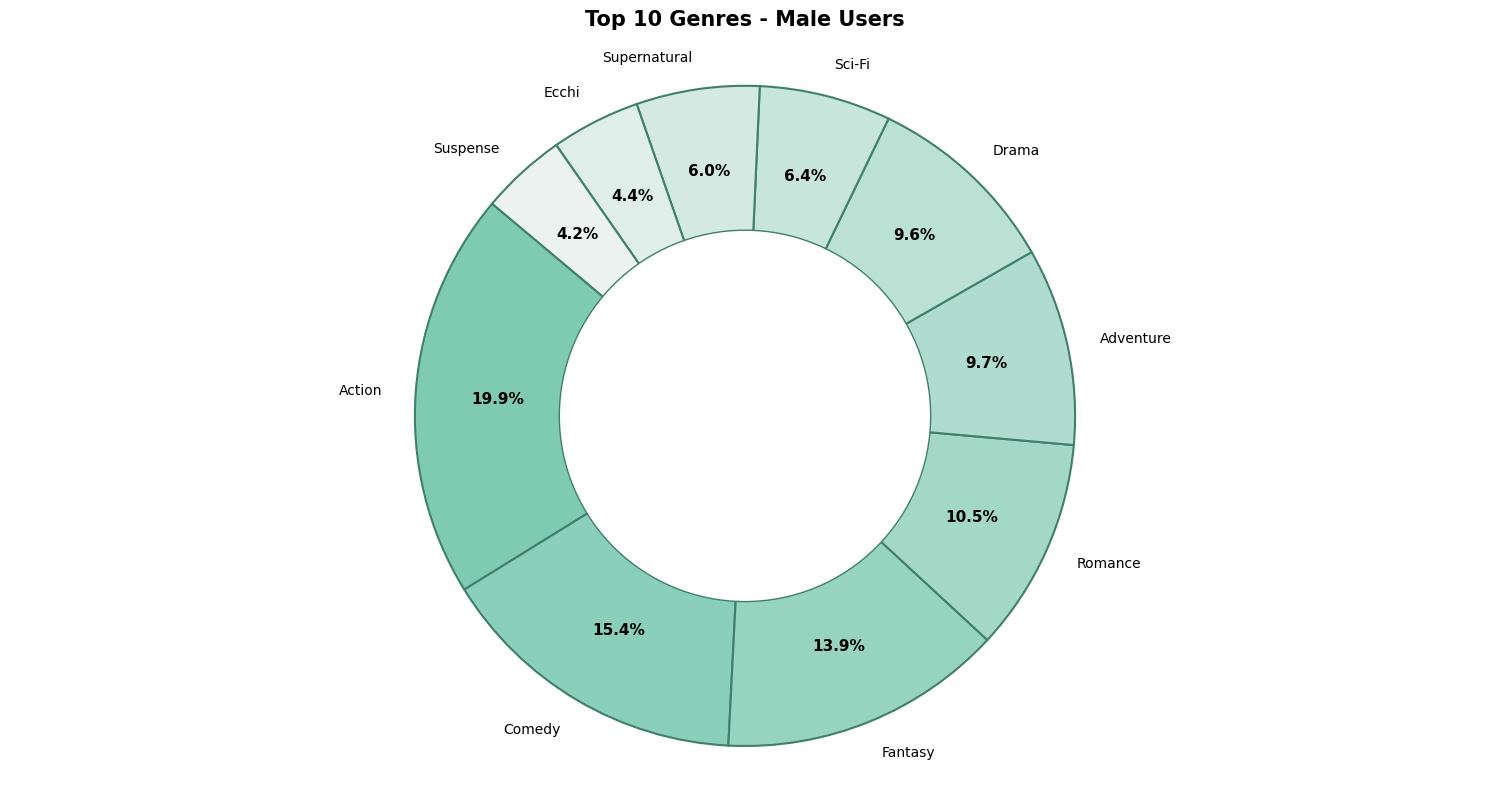

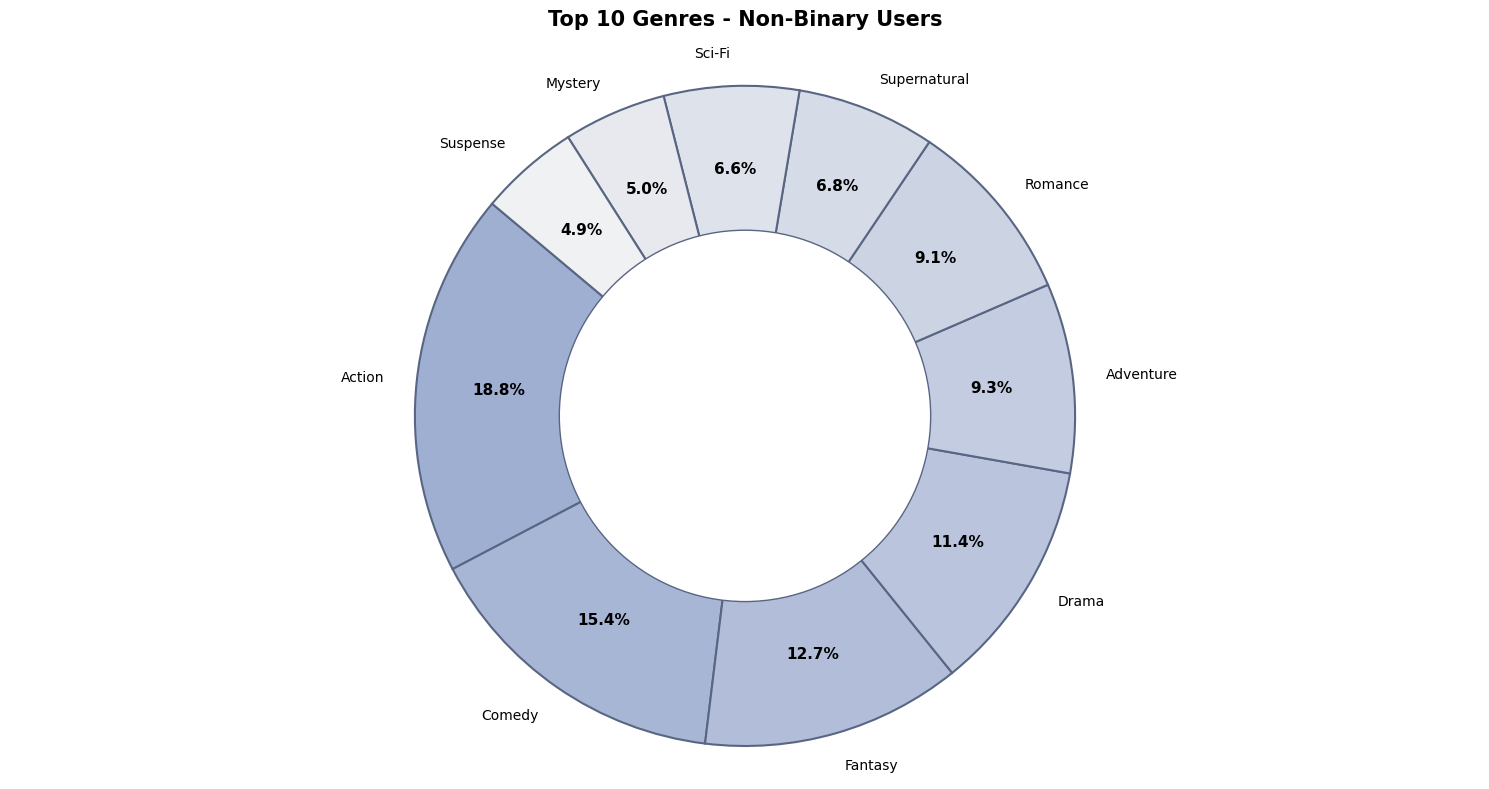

In [22]:
# merge sui dati, prendiamo gli anime con solo stato completated o watching
ratings_copy = ratings_df[ratings_df['status'].isin(['completed', 'watching'])][['username', 'anime_id']]
merged = pd.merge(ratings_copy, profiles_df[['username', 'gender']], on='username')
merged = merged.groupby(['gender', 'anime_id']).size().reset_index(name='view_count')
merged = pd.merge(merged, details_df[['mal_id', 'genres']], left_on='anime_id', right_on='mal_id')
# esplodiamo i generi
merged['genres'] = merged['genres'].apply(eval)
df_temp = merged.explode('genres')
# conteggio di generi per gender
top_genres_gender = df_temp.groupby(['gender', 'genres'])['view_count'].sum().reset_index(name='total_views')
# dividiamoli per genere
top_genre_male = top_genres_gender[top_genres_gender['gender'] == 'Male'].nlargest(10, 'total_views')
top_genre_female = top_genres_gender[top_genres_gender['gender'] == 'Female'].nlargest(10, 'total_views')
top_genre_nb = top_genres_gender[top_genres_gender['gender'] == 'Non-Binary'].nlargest(10, 'total_views')
# per non affollare troppo il codice utilizzo una funzione per visualizzare i 3 grafici
plot_genre_by_gender(top_genre_female, top_genre_male, top_genre_nb)

>**Analisi Complessiva**  
Da quanto emerso in precedenza le *Comedy* sono gli anime più prodotti in assoluto, ma la realtà dei dati ci dice un'altra cosa: gli anime  
di *Azione* sono i più visti, a prescindere dal genere.  
C'è però un dettaglio particolarmente interessante: anche se il genere *Romance* nasce come il prodotto di punta per il target femminile,  
alla fine sono i maschi a guardarlo di più, facendolo schizzare al terzo posto della loro classifica.  
Le femmine mediamente preferiscono molto di più il genere *Drama* rispetto a tutti gli altri utenti.  
In pratica, i gusti degli utenti sono molto più liberi di quanto dicano le etichette. 

### Età media degli utenti

Qual è l'età media degli utenti che valutano e guardano anime?
- Per questa analisi ho rimosso i valori anomali per evitare che account con date di nascita errate falsassero la media.

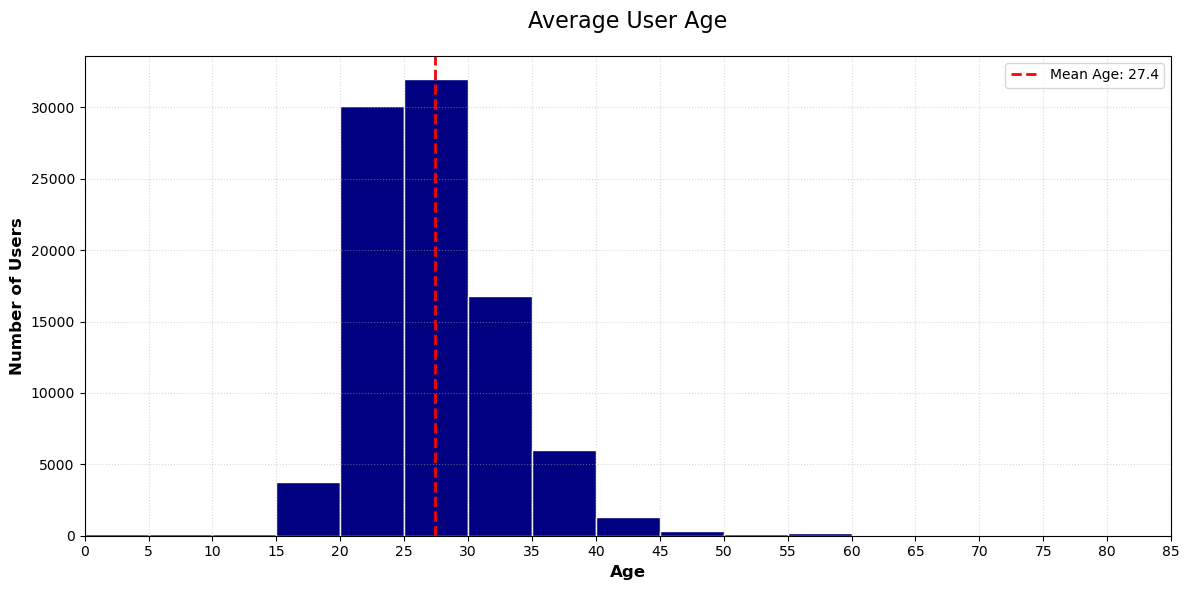

In [23]:
profiles_copy = profiles_df.copy()
# prendiamo la data di oggi per il calcolo esatto
today = pd.Timestamp('today')
# escludiamo le date bizzarre
profiles_copy = profiles_copy[(profiles_copy['birthday'].dt.year >= 1900) & (profiles_copy['birthday'] <= today)]
ages = (today - profiles_copy['birthday']).dt.days // 365 
mean_age = ages.mean()
# creazione grafico
plt.figure(figsize=(12,6))
plt.grid(linestyle=':', alpha=0.5)
plt.hist(ages.dropna(), bins=range(0, 90, 5), color='navy', edgecolor='white')
# linea della media
plt.axvline(mean_age, color='red', linestyle='--', linewidth=2, label=f'Mean Age: {mean_age:.1f}')
# personalizzazione assi
plt.title('Average User Age', fontsize=16, pad=20)
plt.xlabel('Age', fontsize=12, fontweight='bold')
plt.ylabel('Number of Users', fontsize=12, fontweight='bold')
plt.xlim(0, 75)
plt.xticks(range(0, 90, 5))
plt.legend(frameon=True)

plt.tight_layout()
plt.show()

Dando un'occhiata alla distribuzione, notiamo che l'età media degli utenti si aggira intorno ai 27 anni.  
Questo rompe uno stereotipo: la community è composta per la maggior parte da adulti e non da ragazzini, come si tende spesso a pensare.

---
Ma quali sono le demografiche (nonchè i target di riferimento) più viste nelle diverse fasce d'età? Le preferenze degli utenti rispetteranno i target a cui hanno pensato gli ideatori e i produttori?

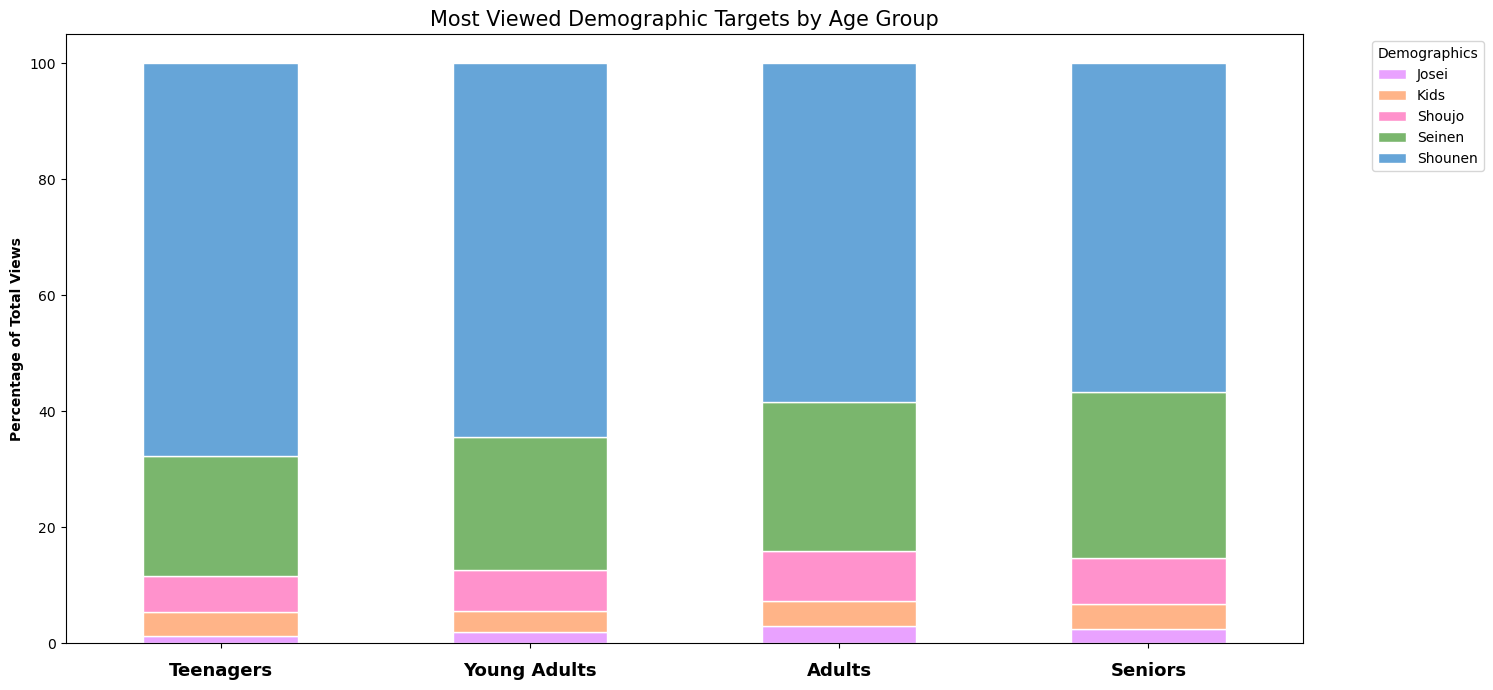

In [24]:
profiles_copy = profiles_df.copy()
# separo le diverse età in 4 fasce
profiles_copy['age'] = 2026 - profiles_copy['birthday'].dt.year
bins = [10, 20, 30, 50, 80]
labels = ['Teenagers', 'Young Adults', 'Adults', 'Seniors']
profiles_copy['age_group'] = pd.cut(profiles_copy['age'], bins=bins, labels=labels)
# trovo le demografiche
details_copy = details_df[['mal_id', 'demographics']].copy()
details_copy['demographics'] = details_copy['demographics'].apply(eval)
details_copy = details_copy.explode('demographics')
# merge tra i dati
ratings_copy = ratings_df[ratings_df['status'].isin(['completed', 'watching'])][['username', 'anime_id']]
ratings_copy = pd.merge(ratings_copy, profiles_copy[['username', 'age_group']], on='username')
merged_final = pd.merge(ratings_copy, details_copy, left_on='anime_id', right_on='mal_id')
# assegnazione colori
color_map = {'Shounen': "#66A5D8",  'Seinen': "#7AB66D",  'Shoujo': "#FF92CC",   'Josei': "#E9A2FF",   'Kids': "#FFB488"  }
# in percentuale
ct = merged_final.groupby(['age_group', 'demographics'], observed=True).size().unstack(fill_value=0)
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
category_order = ct_norm.sum().sort_values(ascending=True).index
ct_norm = ct_norm[category_order]
# creazione grafico
ax = ct_norm.plot(kind='bar', stacked=True, figsize=(15, 7), color=color_map, edgecolor='white')
plt.title('Most Viewed Demographic Targets by Age Group', fontsize=15)
plt.xlabel('')
plt.ylabel('Percentage of Total Views', fontweight='bold')
plt.legend(title='Demographics', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
ax.tick_params(axis='x', which='major', pad=10) 
ax.set_xticklabels(labels, fontweight='bold', fontsize=13)
ax.grid(False)
plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.show()

>**Analisi Complessiva**  
Emerge subito che gli *Shonen* sono i più visti in assoluto; nonostante nel mercato esistano numericamente più titoli destinati ai bambini, gli *Shonen* rappresentano la vera colonna portante del mondo anime. Titoli come *Hunter x Hunter*, *Fullmetal Alchemist: Brotherhood*  e *Naruto* hanno saputo appassionare un pubblico enorme, superando genere e età.  
*Seinen* e *Josei*, come previsto, sono più popolari tra *Adult* e *Senior* che tra i ragazzi, confermando che i contenuti maturiraggiungono il loro pubblico ideale. Stranamente anche i *Shoujo* sembrano essere più apprezzati dagli utenti più grandi, mentre *Kids* invece è la categoria più costante: la sua percentuale resta quasi identica in tutte le fasce d'età.

### Paesi di provenienza degli utenti

Come si distribuiscono geograficamente gli utenti?  
La mappa sottostante realizzata con GeoPandas ci permette di evidenziare visivamente i paesi con più densità di utenti.

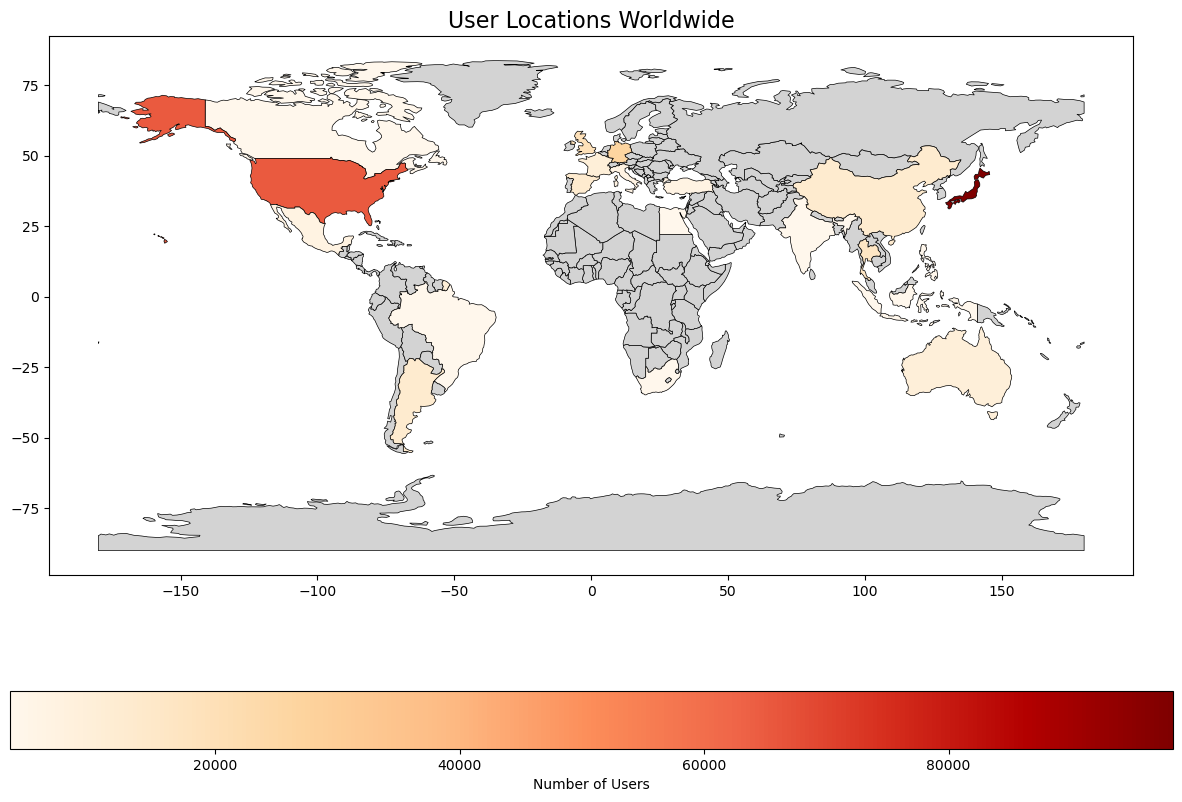

In [25]:
# cerchiamo dove si trovano gli utenti e contiamo per paese
profiles_loc = profiles_df["location"].value_counts().reset_index().copy()
profiles_loc.columns = ['location', 'count']
# chiamo la funzione per le impostazioni di geopandas
world_users = plot_location(profiles_loc)
world_users['count'] = world_users['count'].fillna(0)
# dividiamo in paesi senza utenti e con 
world_zero = world_users[world_users['count'] == 0]
world_nonzero = world_users[world_users['count'] > 0]
# creazione grafico: per i paesi senza utenti apparirà grigio
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
world_zero.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.5)
world_nonzero.plot(column='count', ax=ax, legend=True,cmap='OrRd', edgecolor='black', linewidth=0.5,
                    legend_kwds={'label': "Number of Users", 'orientation': "horizontal"})
ax.grid(False)
ax.set_title('User Locations Worldwide', fontsize=16)
plt.show()

Sebbene gli anime siano un prodotto culturale giapponese, la loro diffusione ha creato una grande community globale.  
Analizzando la provenienza degli utenti, emerge una forte densità in Giappone e negli Stati Uniti, che si confermano i due pilastri della community degli anime.

--- 
In che modo varia il voto medio tra i vari paesi? Scopriamo dove si trovano le community più esigenti e quelle più generose del mondo.

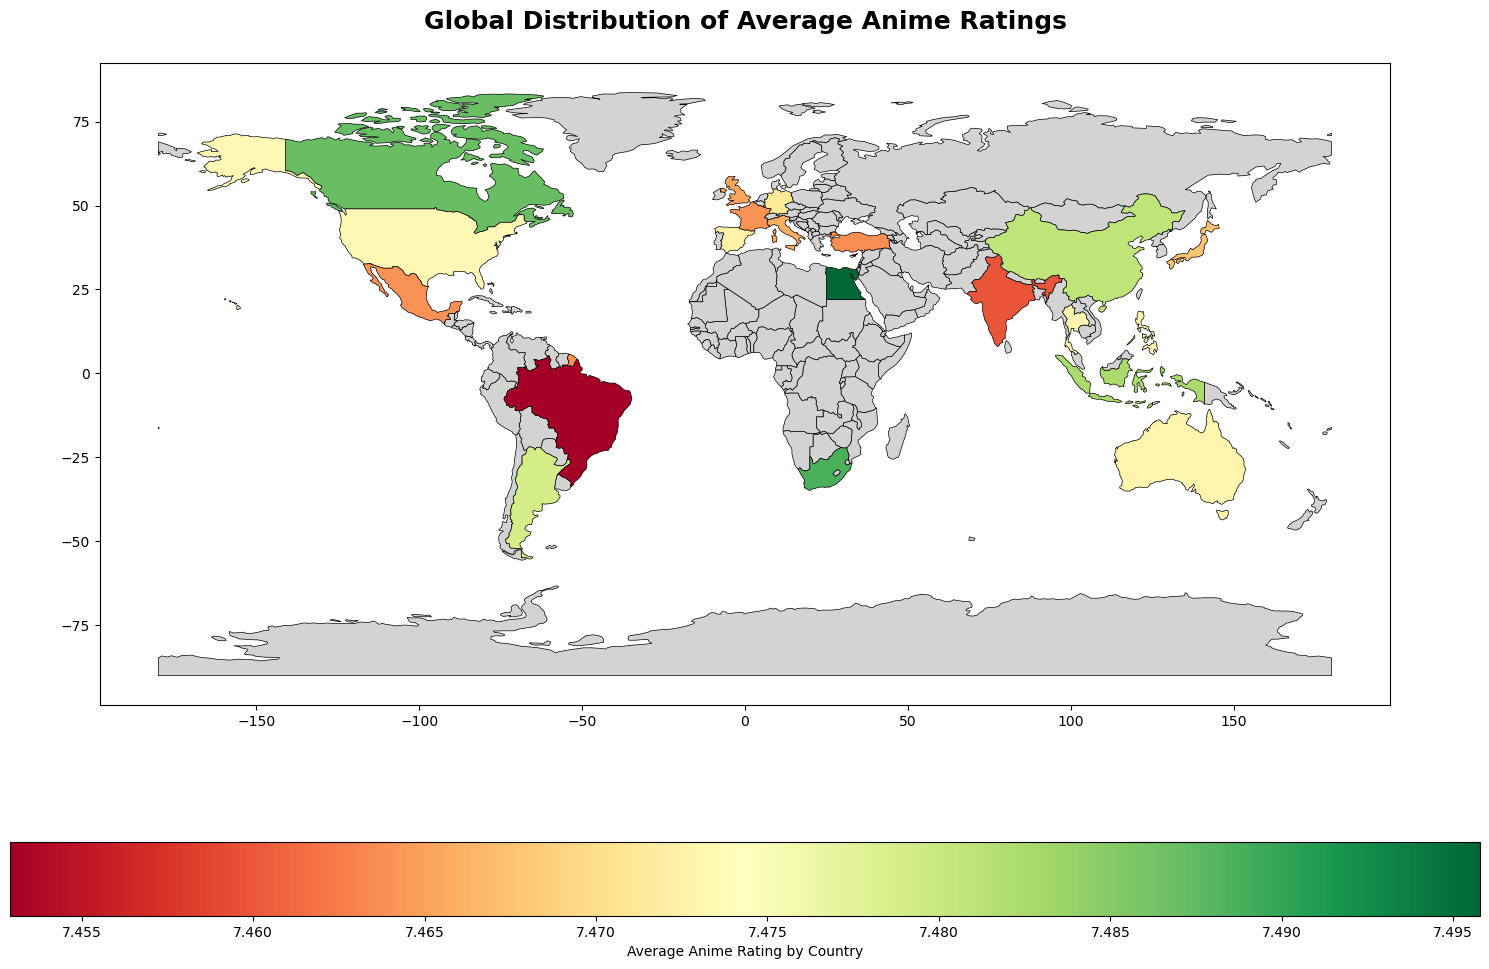

In [26]:
# cerchiamo dove si trovano gli utenti e come votanno
mapping_user_location = profiles_df.set_index('username')['location'].to_dict()
ratings_geo = ratings_df[['username', 'anime_id']].copy()
ratings_geo['location'] = ratings_geo['username'].map(mapping_user_location)
ratings_geo.dropna(subset=['location'], inplace=True)
scoring_merged = ratings_geo.merge(details_df[['mal_id', 'score']], left_on='anime_id', right_on='mal_id')
country_stats = scoring_merged.groupby('location').agg(avg_rating=('score', 'mean'),total_votes=('score', 'count')).reset_index()
# chiamo la funzione per le impostazioni di geopandas
world_map_data = plot_location(country_stats)
world_map_data['total_votes'] = world_map_data['total_votes'].fillna(0)
# dividiamo in paesi senza utenti che votano e con 
world_empty = world_map_data[world_map_data['total_votes'] == 0]
world_active = world_map_data[world_map_data['total_votes'] > 0]
# creazione grafico: per i paesi senza voti apparirà grigio
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
world_empty.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.5)
world_active.plot(column='avg_rating', ax=ax, legend=True,cmap='RdYlGn', edgecolor='black', linewidth=0.5,
                  legend_kwds={'label': "Average Anime Rating by Country", 'orientation': "horizontal"})
ax.grid(False)
ax.set_title('Global Distribution of Average Anime Ratings', fontsize=18, fontweight='bold', pad=25)

plt.tight_layout()
plt.show()

>**Analisi Complessiva**  
Nonostante le differenze culturali, i dati mostrano che i fan di tutto il mondo votano in modo quasi identico.  
L'Egitto emerge per un soffio come il paese più generoso, mentre il Brasile si posiziona come il più severo per quella poca differenza individuata.

### Direttori e creatori preferiti dagli utenti

In base alle preferenze degli utenti, identifichiamo i 10 registi e original creator più apprezzati e analizziamo come la loro produzione si distribuisce tra i diversi generi di anime.

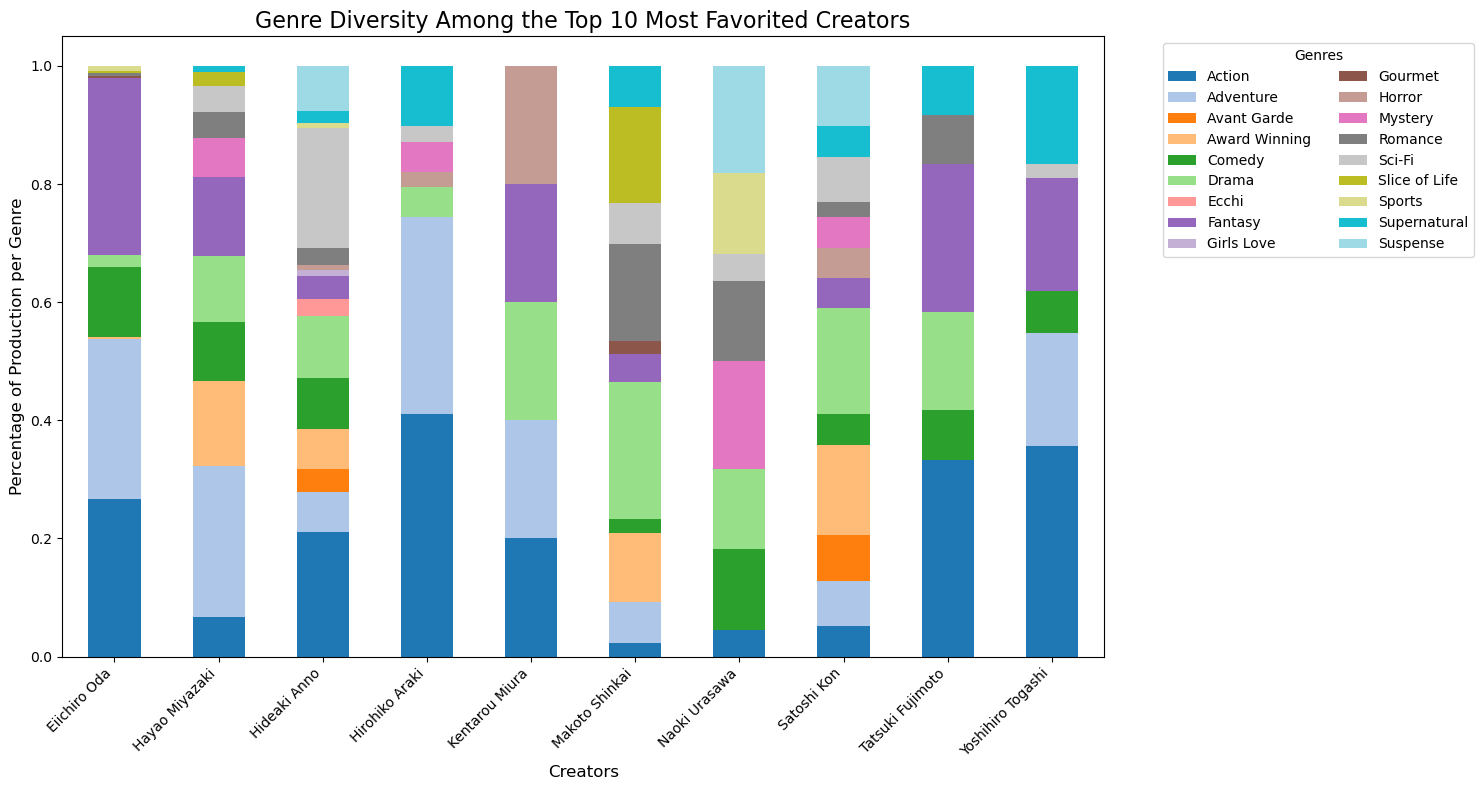

In [27]:
# Individuiamo i Registi/Original Creators in base a quanti favoriti hanno
df_favs = favs_df[favs_df['fav_type'] == 'people'].copy()
fav_counts = df_favs.groupby('id').size().reset_index(name='favorite_count')
fav_person = person_anime_works_df.merge(fav_counts, left_on='person_mal_id', right_on='id', how='inner')
fav_person = fav_person.merge(person_details_df[['person_mal_id', 'name']], on='person_mal_id')
# molte volte ci sono doppiatori che fanno anche da Registi/Original Creators ma non sono riconosciuti per questo, quindi li escludo
va_counts = person_voice_works_df.groupby('person_mal_id').size().reset_index(name='voice_roles_count')
voice_actors_ids = va_counts[va_counts['voice_roles_count'] > 5]['person_mal_id'].unique()
directors = fav_person[~fav_person['person_mal_id'].isin(voice_actors_ids)]
# escludiamo gli altri ruoli
directors = directors[directors['position'].str.contains('Original Creator|Director', case=False, na=False)]
# top 10 registi
top = (directors.groupby(['person_mal_id', 'name'])['favorite_count'].first().nlargest(10).reset_index().sort_values(by='favorite_count', ascending=True))
# troviamo i generi
genre_tot = details_df[['mal_id', 'genres']].copy()
genre_tot['genres'] = genre_tot['genres'].apply(eval)
genre_tot = genre_tot.explode('genres')
# prendiamo i top 10 registi e quante volte usano un genere
top_10_names = top['name'].tolist()
director_genres = directors[directors['name'].isin(top_10_names)].merge(genre_tot, left_on='anime_mal_id', right_on='mal_id', how='inner')
# conteggio
genre_counts = director_genres.groupby(['name', 'genres']).size().unstack(fill_value=0)
genre_percents = genre_counts.div(genre_counts.sum(axis=1), axis=0)
# creazione grafico
fig, ax = plt.subplots(figsize=(15, 8))
genre_percents.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
plt.title('Genre Diversity Among the Top 10 Most Favorited Creators', fontsize=16)
plt.xlabel('Creators', fontsize=12)
plt.ylabel('Percentage of Production per Genre', fontsize=12)
plt.legend(title='Genres', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

>**Analisi Complessiva**  
Alcuni artisti, come Satoshi Kon, sembrano esplorare in modo equilibrato diversi generi, mentre altri, come Araki e Oda, tendono a concentrarsi su tematiche specifiche. 

### Confronto tra i consigliati dagli utenti

Questo grafico esplora la relazione tra il numero di raccomandazioni totali effettuate dagli utenti e la loro distribuzione dei voti.

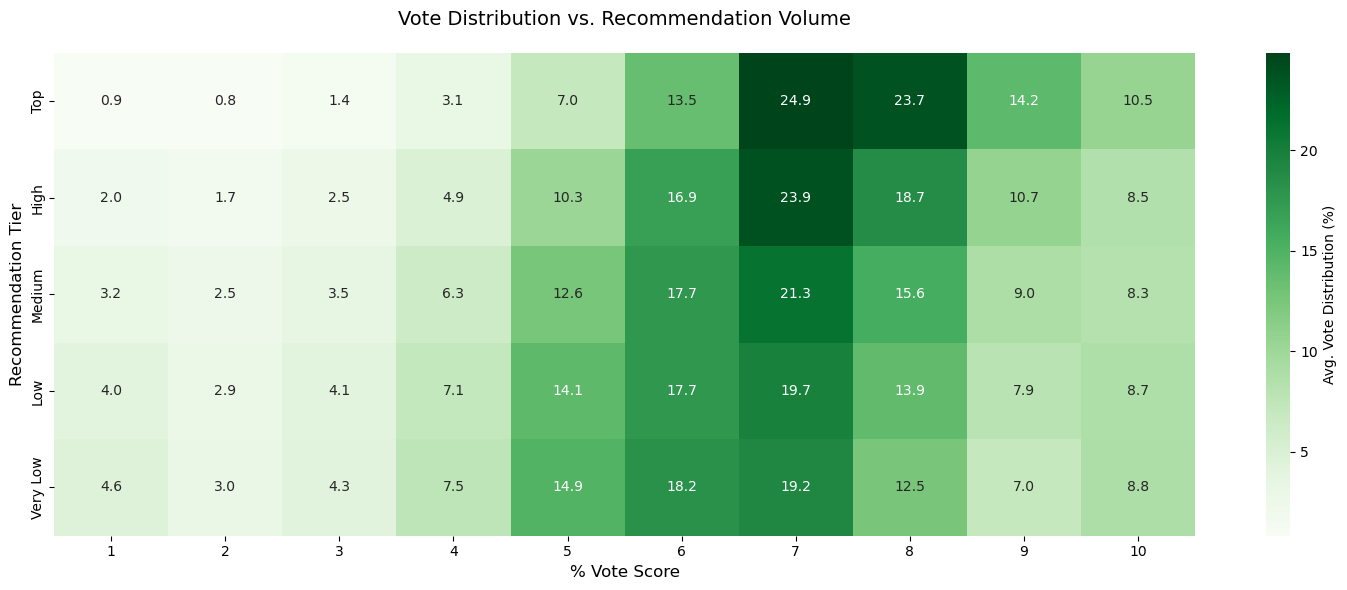

In [28]:
# conteggio raccomandazioni
rec_count = recommendations_df['mal_id'].value_counts().reset_index()
rec_count.columns = ['mal_id', 'total_recs']
# uniamo con le percentuali di voto di stats_df
score_rec = pd.merge(rec_count, stats_df, on='mal_id')
# dividiamo gli anime in base a quante volte sono stati raccomandati 
# (ogni gruppo rappresenta il 20% degli anime, dai meno consigliati ai "Top Recommended")
score_rec['rec_rank'] = score_rec['total_recs'].rank(method='first')
score_rec['rec_group'] = pd.qcut(score_rec['rec_rank'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Top'])
# per ogni gruppo di popolarità, calcoliamo la media delle percentuali di ogni voto.
score_cols = [f'score_{i}_percentage' for i in range(1, 11)]
heatmap_data = score_rec.groupby('rec_group', observed=False)[score_cols].mean()
heatmap_data = heatmap_data.iloc[::-1]
# rinominiamo le colonne per una lettura pulita (1, 2, 3...)
heatmap_data.columns = [str(i) for i in range(1, 11)]
# creazione grafico
plt.figure(figsize=(15, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="Greens", cbar_kws={'label': 'Avg. Vote Distribution (%)'})
plt.title('Vote Distribution vs. Recommendation Volume', fontsize=14, pad=20)
plt.xlabel('% Vote Score', fontsize=12)
plt.ylabel('Recommendation Tier', fontsize=12)
plt.tight_layout()
plt.show()

>**Analisi Complessiva**   
L'analisi dei dati mette in luce un legame diretto tra il livello di raccomandazione di un anime e il modo in cui viene valutato. 
Gli anime più raccomandati mostrano una forte concentrazione di voti nella fascia alta, tra il 7 e il 10. 
Al contrario, scendendo verso i titoli meno suggeriti, la distribuzione cambia: le percentuali nelle fasce medie e basse (1-6) aumentano.
Tuttavia, il dato più interessante emerge dai titoli meno raccomandati in assoluto (Very Low): la percentuale di voti 10 è sensibilmente più alta rispetto ai livelli intermedi (Low, Medium e High). Questo indica la presenza di titoli di nicchia, però molto amati, che alzano la distribuzione media dei voti.